# Kumara variety allocation — Bayesian hierarchical model

**Decision:** how many hectares of each variety to plant this coming season.

**Approach.** Margin per hectare splits into three quantities, each estimated with its own
partially pooled hierarchical model in PyMC:

$$\text{margin/ha} \;=\; \underbrace{\frac{\text{sellable bins}}{\text{ha}}}_{\text{Model A — Bin Tally}}
\times \underbrace{\frac{\text{kg}}{\text{bin}}}_{\text{Model B — Packout}}
\times \underbrace{\frac{\$_\text{net}}{\text{kg}}}_{\text{Model C — Packout}}
\;-\; \text{cost/ha}$$

What the modelling buys you:

1. **Thin varieties borrow strength.** Owairaka Red and Beauregard have a decade or more of
   records; Murasaki, Honeysweet and Bellevue have a handful of rows. Partial pooling shrinks thin
   varieties toward the farm-wide mean rather than trusting one lucky paddock.
2. **Season is a shared shock.** A bad year hits every variety and a short-supply year lifts every
   price (2023 stands out). Sharing the season effect keeps varieties correlated, so the optimiser
   does not overrate diversification.
3. **Next season is unobserved.** The forecast draws a brand-new season effect, so its intervals
   include year-to-year volatility, not just parameter uncertainty.
4. **Rainfall makes the season forecastable.** Yield responds to three windows (**Oct–Dec**
   planting, **Jan–Feb** growth, **Mar–May** harvest); price to **Oct–Jan** and **Feb–May**
   (section 4).
5. **Lost paddocks are counted once.** Yield is per hectare *lifted*. The share of planted area a
   wet season stops you lifting is measured separately from the Bin Tally's abandonment flags and
   applied in the forecast (section 8.1). In 2023 Hodgson lost 57% of its planted area, Te Kowhai 5%.
6. **The plan is for a site.** Variety yields can differ between Hodgson and Te Kowhai
   (section 5.3), so `PLAN_SITE` can change the mix, not just the profit.
7. **Price premiums can drift.** Beauregard's has slipped as its Premium grade-out fell; the
   forecast starts from where each premium stands now (section 7.0).
8. **A new variety can enter on your judgement.** Bellevue has no price history, so it is
   simulated as Beauregard scaled by your expectation (sections 3.3 and 11.6).

The forecast is a matrix of margin-per-hectare draws (draws × varieties), which feeds a
**portfolio optimisation**: the allocation that maximises risk-adjusted profit within your total
area and per-variety limits.

---
### Run order
Top to bottom. Sections 1–4 load the data (including rainfall), 5–7 fit the three models, 8
simulates next season under a rainfall scenario, and 9–11 optimise and report: **11.3** is the
drought comparison and **11.5** says which hectare figures are firm. **Read the caveats in
section 12 before acting on the numbers.**

### Judgement calls
Four inputs are assumptions, not measurements:
- `COST_PER_HA` does not affect the mix at all (section 11.1).
- `MIN_AREA_HA` / `MAX_AREA_HA` affect it a great deal.
- The 900 mm threshold in `HARVEST_LOSS`, below which a season is assumed to cost no paddocks
  (section 8.1). How fast losses climb above it is fitted; where the climb starts is not, because
  only one season has crossed it.
- Your expectation for Bellevue in `NEW_VARIETY_BELIEFS` (section 11.6).

### After a data refresh
The Bin Tally and Packout exports are still being cleaned. The data cells print what they loaded,
mapped and dropped, and why. **Read those lines after a refresh**, and re-check the figures quoted
in the text (sections 3, 4, 8.1, 11 and 12). They were written against the export current at the
time.

## 1. Setup and decision knobs

Everything you might change is in the next cell. `COST_PER_HA`, `MIN_AREA_HA` and `MAX_AREA_HA`
are **your inputs, not data**: neither the Bin Tally nor the Packout files record costs or market
limits. The area limits drive the recommendation; the cost figure cannot (section 11.1).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import pytensor.tensor as pt
from scipy import optimize

warnings.filterwarnings("ignore")
RNG = np.random.default_rng(20260913)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
})

# ---------------------------------------------------------------- paths
BASE = Path.cwd()
BIN_TALLY_DIR = BASE / "Bin_Tally_Data"
PACKOUT_DIR   = BASE / "Packout_Sheet_Data"
RAINFALL_DIR  = BASE / "Rainfall_Data"
OUT_DIR       = BASE / "outputs"; OUT_DIR.mkdir(exist_ok=True)

# ================================================================
#                        DECISION KNOBS
# ================================================================
PLANTING_SEASON = 2027          # harvest-season label for the crop being planted now

TOTAL_AREA_HA   = 15.0          # total hectares you will plant

# Varieties to consider. Trim to what you can actually source seed for.
# Honeysweet is out: seed is no longer available. Its records stay in the models, where
# they still help estimate how much varieties differ from one another.
CANDIDATES = ["Owairaka Red", "Beauregard", "Gold", "Purple Dawn", "Murasaki", "Bellevue"]

# Site to plan for: "Te Kowhai (90 Te Kowhai Road)", "Hodgson (91 Hodgson Road)",
# or "average" to plan at the farm-wide average site effect.
PLAN_SITE = "Hodgson (91 Hodgson Road)"

# Let each variety do better or worse at each site (partially pooled - section 5.3).
# Without it the site scales every variety's yield by the same factor, so PLAN_SITE could
# move the profit but never the mix.
VARIETY_SITE_INTERACTION = True

# ---- YOUR COST ASSUMPTION ($/ha, all variable costs to the packhouse door).
# NOT from the data files. Costs do not vary by variety (they vary by paddock),
# so this is a single number - and see section 11.1: with total area fixed, the
# cost level cannot change the recommended MIX at all, only the profit you book
# against it. Getting it exactly right matters for budgeting, not for the plan.
COST_PER_HA = 12000.0

# ---- Constraints (hectares). Floors keep seed lines alive or honour contracts;
# ceilings cap market demand or agronomic limits (rotation, soil type).
# These values are PLACEHOLDERS and they drive the answer hard: the model will
# happily push a variety to its ceiling, so the ceiling is often what decides the
# plan. Set them to the real limits on seed, market and rotation before you read
# the recommendation as a recommendation.
MIN_AREA_HA = {"Owairaka Red": 1.0}
MAX_AREA_HA = {"Gold": 0.5, "Murasaki": 3.0, "Purple Dawn": 5.0, "Bellevue": 2.0}

# ---- NEW VARIETIES WITHOUT PRICE DATA: your expectation, relative to a known variety.
# Bellevue is simulated AS Beauregard - same drought response, season swings, site
# effect, bin weight and price risk, with its own paddock luck - then scaled by your
# view of how much better it is (sections 3.3 and 11.6).
#   yield_vs_like  yield ratio to the "like" variety in a drought and in a wet season
#                  (the 5th and 90th percentile seasons on record); interpolated in
#                  between and held flat beyond. yield_sd is how unsure you are, on the
#                  log scale: 0.10 is roughly +/-20% at 95%.
#   premium_pp     extra percentage points of the crop graded Premium, with every grade
#                  paid the same as the "like" variety. Section 3.3 turns this into $/kg.
#                  YOUR NUMBER IS NEEDED HERE - 10 +/- 5 points is a placeholder.
NEW_VARIETY_BELIEFS = {
    "Bellevue": {"like": "Beauregard",
                 "yield_vs_like": {"drought": 1.05, "wet": 1.20}, "yield_sd": 0.10,
                 "premium_pp": 10.0, "premium_pp_sd": 5.0},
}

# ---- RAINFALL --------------------------------------------------
# October-May rainfall, sliced into windows separately for each model (RAIN_WINDOWS).
USE_RAINFALL = True
RAIN_SITE    = "Ruawai"        # or "Dargaville" - they correlate at 0.988
# Shape of the rainfall response, chosen SEPARATELY for yield and price - they are
# different physical relationships and the wrong shape breaks badly at the dry end.
# See section 4.2; do not set price to "quadratic" without reading it.
# "hinge"     - flat until a threshold, then linear. Nothing happens until it is too
#               wet, then the crop collapses. Matches the physical story and, unlike a
#               quadratic, does not invent a drought effect by symmetry. See section 4.2.
# "linear"    - monotone.
# "quadratic" - a genuine interior optimum. Dangerous at the edges; read 4.2 first.
RAIN_FORM = {"yield": "linear",      # with three windows each one is monotone
             "price": "linear"}      # monotone: more rain -> less supply -> higher price
RAIN_HINGE_MM = {"total": 800.0, "early": 450.0, "late": 400.0,
                 "plant": 350.0, "grow": 250.0, "harvest": 300.0}   # thresholds, mm

# How to slice the season, per model (see section 4.2):
#   "season" - one Oct-May total
#   "split"  - early (Oct-Jan) + late (Feb-May)
#   "three"  - plant (Oct-Dec) + grow (Jan-Feb) + harvest (Mar-May)
# Yield uses "three": planting rain, growing rain and harvest rain do different things.
# Price keeps "split": it responds to Feb-May as a block and only 12 seasons are priced.
RAIN_WINDOWS = {"yield": "three", "price": "split"}

# ---- HARVEST COMPLETION: the share of PLANTED area actually lifted, by season and site.
# Abandoned paddocks are flagged in the Bin Tally, so this is measured, not assumed
# (section 2). It calibrates the abandonment curve below. It is NOT used to rescale
# yields - doing both would count a wet year's lost paddocks twice.
# This dict only OVERRIDES the recorded figure; leave it empty to use the data.
HARVEST_COMPLETION_OVERRIDE = {}     # e.g. {(2023, "Hodgson"): 0.35}

# ---- ABANDONMENT RISK IN THE FORECAST: the share of planted area you expect to LOSE,
# as a function of how wet the season turns out. Nothing is lost below threshold_mm;
# above it, losses climb by loss_per_100mm for every extra 100 mm, up to max_loss.
# "fit" takes the slope from the recorded abandonment at PLAN_SITE (section 8.1) - in
# 2023 Hodgson lost more than half its planted area and Te Kowhai almost none, so the
# site matters. A number here overrides the fit. Only 2023 has recorded abandonment,
# so the threshold is a judgement call; section 8.1 says why it sits where it does.
HARVEST_LOSS = {"driver": "total",        # "total" | "grow" | "harvest" - see section 8.1
                "threshold_mm": 900.0,    # no losses below this
                "loss_per_100mm": "fit",  # "fit", or area lost per 100 mm above it
                "max_loss": 0.90}
# Let each variety's PRICE premium drift from season to season (a random walk, anchored at
# the latest season), so the forecast starts from where a variety's price stands now rather
# than its 12-year average. The model learns how fast premiums drift; if they do not, it
# reduces to a fixed premium. Section 7.
PRICE_PREMIUM_DRIFT = True

RAIN_VARIETY_INTERACTION = True   # do varieties respond to rain differently? This is what
                                  # decides whether a drought changes the MIX or only the total.

# The season you are planting into. A forecast is uncertain, so give it a spread:
# the scenario is drawn per posterior draw, propagating that uncertainty end to end.
#   "drought" | "dry" | "normal" | "wet" | "climatology" (draw from history), or a number in mm
RAIN_SCENARIO       = "drought"
RAIN_SCENARIO_SD_MM = 90.0     # 1 sd of forecast error, in mm

# ---- Risk preference for the headline recommendation.
RISK_MEASURE   = "cvar"   # "mean" (risk-neutral), "meanvar", or "cvar"
RISK_AVERSION  = 1.0      # weight on the downside penalty; 0 = risk-neutral
CVAR_ALPHA     = 0.20     # CVaR averages the worst 20% of seasons

# ---- How much idiosyncratic paddock noise survives into a whole-block average.
# Spreading a variety over more paddocks averages away block-level luck.
BLOCKS_PER_VARIETY = 2.0

# Typical size of one block you plant (ha). Yield noise is fitted as partly shrinking with
# paddock area - a 0.1 ha strip is far noisier than a 2 ha paddock - so the forecast needs
# to know how big your blocks are. Most Hodgson paddocks are 1.6-1.7 ha.
PLAN_BLOCK_HA = 1.6

# ---- Price basis: "computed" = total_payout / nett_kgs (mechanically meaningful),
# "sheet" = the sheet's own printed avg_nett_per_kg. Section 3 compares them.
PRICE_BASIS = "computed"

# ---- Pin a known price or bin weight for a variety the packout sheets don't cover
# (e.g. a specialty line sold outside Kaipara). Units: $/kg and kg/bin, for a TYPICAL
# season - the season-to-season swings and the rainfall effect still apply on top.
# Leave empty to let the model shrink them to the farm-wide mean with wide uncertainty.
PRICE_OVERRIDE  = {}   # e.g. {"Murasaki": 2.40}
KGBIN_OVERRIDE  = {}   # e.g. {"Murasaki": 600.0}

# ---- Random seed for the forecast. Section 8 and every re-optimisation after it
# simulate from this seed, so the headline plan and the scenario table in 11.3 see the
# same simulated seasons and agree exactly.
FORECAST_SEED = 7

# ---- Sampler
SAMPLE_KW = dict(draws=1500, tune=1500, chains=4, cores=1, target_accept=0.95,
                 random_seed=20260913, progressbar=False)

print(f"PyMC {pm.__version__} | ArviZ {az.__version__} | pandas {pd.__version__}")
print(f"Planning {TOTAL_AREA_HA:.0f} ha for the {PLANTING_SEASON} season across "
      f"{len(CANDIDATES)} candidate varieties.")

g++ not available, if using conda: `conda install gxx`


PyMC 6.0.1 | ArviZ 1.1.0 | pandas 3.0.1
Planning 15 ha for the 2027 season across 6 candidate varieties.


## 2. Bin Tally → yield observations (sellable bins per hectare)

One observation per **paddock × season × variety**. Where varieties shared a paddock, its area is
split in proportion to rows harvested (else total bins, else evenly), as the Bin Tally README
documents. The cell uses `bin_tally_paddock_season_variety_area.csv` when present, otherwise
reconstructs it from the harvest log, and reports the gap between the two when it has both.
`sellable_bins` excludes walked bins.

**A wet season hurts in two ways, measured separately:**

- **Yield per hectare lifted**: `sellable_bins / area_ha` on harvested paddocks. The yield model
  (section 5) learns from this.
- **Harvest completion**: the share of *planted* area lifted, by season and site, from the Bin
  Tally's `abandoned` flag. The abandonment curve (section 8.1) is calibrated on this.

The forecast multiplies the two back together. Also rescaling yields for abandonment would count a
wet year's lost paddocks twice.

Completion is measured by site because abandonment differs by site: in 2023 Hodgson lost 57% of
its planted area and Te Kowhai 5%. Measuring it by area also catches a variety that lost every
paddock, as Gold did in 2023 (so Gold has no 2023 yield row). 2026 has no recorded abandonment, so
its low yields reflect a poor season, not lost paddocks.

In [2]:
tally = pd.read_csv(BIN_TALLY_DIR / "bin_tally_harvest_log.csv")
print(f"harvest log: {len(tally):,} rows, seasons {tally.season.min()}-{tally.season.max()}")

num = ["rows_harvested", "total_bins", "sellable_bins", "area_ha"]
tally[num] = tally[num].apply(pd.to_numeric, errors="coerce")

# Paddocks planted but never lifted are flagged in the Bin Tally. Older exports have no
# flag; there, "no bins at all" is the best available sign of abandonment.
if "abandoned" in tally.columns:
    tally["abandoned"] = (tally.abandoned.astype(str).str.strip().str.lower()
                               .isin(["true", "1", "yes", "y"]))
    print(f"abandonment: from the Bin Tally's 'abandoned' flag "
          f"({int(tally.abandoned.sum())} entries)")
else:
    tally["abandoned"] = tally.total_bins.fillna(0) <= 0
    print("abandonment: no 'abandoned' column in this export - inferred from zero bins")


def site_short(s):
    "Hodgson / Te Kowhai / other, from the Bin Tally's long site names."
    s = str(s)
    return ("Hodgson" if s.startswith("Hodgson") else
            "Te Kowhai" if s.startswith("Te Kowhai") else "other")


# ---- collapse repeat harvest events into one row per paddock-season-variety
grp = (tally.dropna(subset=["paddock", "variety_common_name"])
            .groupby(["season", "paddock", "variety_common_name"], as_index=False)
            .agg(rows_harvested=("rows_harvested", "sum"),
                 total_bins=("total_bins", "sum"),
                 sellable_bins=("sellable_bins", "sum"),
                 paddock_area_ha=("area_ha", "max"),
                 site=("site", "first"),
                 abandoned=("abandoned", "max"),
                 n_events=("season", "size")))


# ---- split each paddock-season's area between the varieties that shared it:
#      by rows harvested, else by total bins, else evenly
key = ["season", "paddock"]
w_rows = grp.rows_harvested.fillna(0.0)
w_bins = grp.total_bins.fillna(0.0)
tot_rows = w_rows.groupby([grp[k] for k in key]).transform("sum")
tot_bins = w_bins.groupby([grp[k] for k in key]).transform("sum")
n_var    = w_rows.groupby([grp[k] for k in key]).transform("size")

share = np.where(
    tot_rows > 0, w_rows / tot_rows.where(tot_rows > 0, 1.0),
    np.where(tot_bins > 0, w_bins / tot_bins.where(tot_bins > 0, 1.0), 1.0 / n_var))

recon = grp.assign(
    weight_basis=np.where(tot_rows > 0, "rows", np.where(tot_bins > 0, "bins", "even")),
    variety_share=share,
    area_ha=grp.paddock_area_ha * share,
).rename(columns={"variety_common_name": "variety"})

# Prefer the Bin Tally's own attribution file when it is present: it is the source of
# truth and absorbs any hand-corrections (e.g. the walked-bins-only entries its README
# flags). Fall back to the reconstruction above, and cross-check when we have both.
AREA_FILE = BIN_TALLY_DIR / "bin_tally_paddock_season_variety_area.csv"
if AREA_FILE.exists():
    # that file carries the sheet's own label AND the common name; keep the common name
    off = (pd.read_csv(AREA_FILE)
             .drop(columns=["variety"])
             .rename(columns={"variety_common_name": "variety"}))
    off = off[["season", "paddock", "variety", "attributed_area_ha", "weight_basis"]]
    yield_df = (recon.drop(columns=["area_ha", "weight_basis"])
                     .merge(off, on=["season", "paddock", "variety"], how="left")
                     .rename(columns={"attributed_area_ha": "area_ha"}))
    chk = yield_df.merge(recon[["season", "paddock", "variety", "area_ha"]],
                         on=["season", "paddock", "variety"], suffixes=("", "_recon"))
    gap = (chk.area_ha - chk.area_ha_recon).abs().max()
    print(f"area source: {AREA_FILE.name} ({len(off)} rows); "
          f"max gap vs our reconstruction {gap:.4f} ha")
    if yield_df.area_ha.isna().any():
        filled = yield_df.merge(recon[["season", "paddock", "variety", "area_ha"]],
                                on=["season", "paddock", "variety"],
                                how="left", suffixes=("", "_r"))["area_ha_r"]
        still = int((yield_df.area_ha.isna() & filled.isna()).sum())
        rescued = int((yield_df.area_ha.isna() & filled.notna()).sum())
        yield_df["area_ha"] = yield_df.area_ha.fillna(filled)
        if rescued:
            print(f"  {rescued} group(s) missing there, recovered from the reconstruction")
        if still:
            print(f"  {still} group(s) have no area in either source - the F-coded Fenney")
            print("  paddocks, whose areas were never recorded; they drop out below")
else:
    yield_df = recon
    print("area source: reconstructed from the harvest log "
          "(bin_tally_paddock_season_variety_area.csv not present)")

before = len(yield_df)
yield_df["site_short"] = yield_df.site.map(site_short)
yield_df["outcome"] = np.where(
    yield_df.abandoned, "abandoned",
    np.where(yield_df.sellable_bins.fillna(0) <= 0, "seed only", "harvested"))

# ---- harvest completion = area lifted / area planted, by season and site. It measures
# abandonment and calibrates the forecast's loss curve (section 8.1). It is deliberately
# NOT used to rescale yields - see the note above this cell.
planted = yield_df[yield_df.area_ha > 0.01].copy()
planted["lifted_ha"] = planted.area_ha.where(planted.outcome != "abandoned", 0.0)
_site = planted.groupby(["season", "site_short"])[["lifted_ha", "area_ha"]].sum()
COMPLETION_SITE = (_site.lifted_ha / _site.area_ha).rename("completion")
_farm = planted.groupby("season")[["lifted_ha", "area_ha"]].sum()
COMPLETION_FARM = (_farm.lifted_ha / _farm.area_ha).rename("completion")
for (s, where), c in HARVEST_COMPLETION_OVERRIDE.items():
    k = (s, site_short(where))
    print(f"  override: {s} {k[1]} completion "
          f"{COMPLETION_SITE.get(k, np.nan):.2f} (data) -> {c:.2f} (yours)")
    COMPLETION_SITE.loc[k] = c

lost = planted[planted.outcome == "abandoned"]
if len(lost):
    print(f"\nabandoned on record: {len(lost)} paddock-variety group(s), "
          f"{lost.area_ha.sum():.1f} ha, seasons {sorted(int(s) for s in lost.season.unique())}")
    for s in sorted(lost.season.unique()):
        for site, r in _site.loc[s].iterrows():
            if site != "other":
                print(f"  {s} {site:<9}  planted {r.area_ha:5.1f} ha, lifted {r.lifted_ha:5.1f} ha"
                      f"  -> {1 - r.lifted_ha / r.area_ha:4.0%} lost")
        f = _farm.loc[s]
        print(f"  {s} whole farm  {1 - f.lifted_ha / f.area_ha:4.0%} lost")
        gone = (set(lost.loc[lost.season == s, "variety"])
                - set(planted.loc[(planted.season == s) & (planted.outcome != "abandoned"),
                                  "variety"]))
        if gone:
            print(f"     {sorted(gone)} lost every paddock that season, so has no {s} yield row.")
            print("     The loss is still counted: abandonment is measured by AREA, whatever")
            print("     the variety (section 8.1).")

yield_df = yield_df[(yield_df.area_ha > 0.01) & (yield_df.sellable_bins > 0)].copy()

# Yield per hectare LIFTED. Abandonment is priced once, separately, in the forecast.
yield_df["bins_per_ha"] = yield_df.sellable_bins / yield_df.area_ha
yield_df["log_yield"]   = np.log(yield_df.bins_per_ha)

print(f"\npaddock-season-variety groups: {before:,}  ->  usable yield observations: {len(yield_df):,}")
print(f"  dropped {before - len(yield_df)}: abandoned, walked or seed-only (no sellable bins),")
print("  or no area on record (Fenney Block)")

display(yield_df.groupby("variety").agg(
    n_obs=("bins_per_ha", "size"), seasons=("season", "nunique"),
    total_ha=("area_ha", "sum"), median_bins_per_ha=("bins_per_ha", "median"),
).round(2).sort_values("n_obs", ascending=False))

harvest log: 814 rows, seasons 2014-2026
abandonment: from the Bin Tally's 'abandoned' flag (9 entries)
area source: bin_tally_paddock_season_variety_area.csv (399 rows); max gap vs our reconstruction 0.0000 ha
  5 group(s) have no area in either source - the F-coded Fenney
  paddocks, whose areas were never recorded; they drop out below

abandoned on record: 9 paddock-variety group(s), 10.2 ha, seasons [2023]
  2023 Hodgson    planted  17.3 ha, lifted   7.5 ha  ->  57% lost
  2023 Te Kowhai  planted   8.6 ha, lifted   8.2 ha  ->   5% lost
  2023 whole farm   40% lost
     ['Gold'] lost every paddock that season, so has no 2023 yield row.
     The loss is still counted: abandonment is measured by AREA, whatever
     the variety (section 8.1).

paddock-season-variety groups: 399  ->  usable yield observations: 324
  dropped 75: abandoned, walked or seed-only (no sellable bins),
  or no area on record (Fenney Block)


,n_obs,seasons,total_ha,median_bins_per_ha
variety,,,,
Owairaka Red,192,13,222.87,17.25
Beauregard,87,12,72.08,26.00
Gold,19,9,4.74,30.00
Purple Dawn,15,7,10.40,31.50
Murasaki,5,3,1.43,24.00
Honeysweet,5,5,1.77,26.40
Bellevue,1,1,0.11,23.30


## 3. Packout → bin weights and net prices

Two quantities per delivery: **kg per bin** (`nett_kgs / bins_tipped`) and **net $/kg**.

**OCR damage.** The Packout README notes that OCR sometimes drops or moves decimal points in dollar
figures but leaves kilograms alone (111 detail rows carry a `dollar_per_kg` above $20). So bin
weights use every delivery, while prices go through a plausibility filter and the sheet's own
reconciliation check (`qa_dollar_per_kg_diff_pct`).

**Unfamiliar labels.** Labels already written as common names (Honeysweet, Murasaki) pass through
the mapping unchanged, and the cell prints any it did not map. A bare `.map()` once silently
dropped every Honeysweet and Murasaki delivery.

**Mislabelled summary pages.** A summary page's variety is often inferred from the page colour or
file name, while the hand-corrected detail file names the variety on every grade line. Where every
line on a page agrees and the summary disagrees, the detail wins (unless the summary label was
itself hand-corrected). On the current export that relabels six deliveries: four Honeysweet pages
and one Gold page filed as Red, and one Beauregard page filed as Gold. They are worth fixing at
source.

**Duplicate scans.** Deliveries with the same date, bins, kilograms and payout are duplicates, and
one copy is kept. If the copies disagree on variety, both are dropped. Currently that is invoice
803 page 2, filed as both Beauregard and Purple Dawn; at $2.12/kg it is almost certainly Purple
Dawn.

In [3]:
pack = pd.read_csv(PACKOUT_DIR / "all_years_summary.csv")
print(f"packout summary: {len(pack):,} deliveries")

# Some summary pages carry the wrong variety label. The detail file (hand-corrected, one
# row per grade line) names the variety on every line, so where all the lines on a page
# agree and the summary says something else, the detail wins - unless the summary label
# was itself corrected by hand.
DETAIL_FILE = PACKOUT_DIR / "all_years_detail.csv"
if DETAIL_FILE.exists():
    _det = pd.read_csv(DETAIL_FILE)
    _kp = ["year_folder", "source_file", "source_page"]
    _dv = (_det.dropna(subset=["variety"]).groupby(_kp).variety
               .agg(lambda x: x.iloc[0] if x.nunique() == 1 else None).dropna()
               .rename("detail_variety").reset_index())
    pack = pack.merge(_dv, on=_kp, how="left")
    fix = pack.detail_variety.notna() & (pack.variety != pack.detail_variety)
    if "variety_source" in pack.columns:
        fix &= pack.variety_source.fillna("") != "user_corrected"
    if fix.any():
        print(f"  relabelled {int(fix.sum())} deliveries to match their own grade lines:")
        for _, r in pack[fix].iterrows():
            was = r.variety if pd.notna(r.variety) else "(blank)"
            print(f"    {r.year_folder} {r.source_file} p{r.source_page}: "
                  f"{was} -> {r.detail_variety}")
        pack.loc[fix, "variety"] = pack.loc[fix, "detail_variety"]
    pack = pack.drop(columns="detail_variety")

# Packout sheets mostly label varieties Red/Orange/Gold/Purple; the Bin Tally uses
# common names. Anything already written as a common name (Honeysweet, Murasaki, ...)
# passes straight through - do NOT use a bare .map() here, it would silently turn every
# unrecognised label into NaN and drop those deliveries.
PACKOUT_TO_COMMON = {"Red": "Owairaka Red", "Orange": "Beauregard",
                     "Gold": "Gold", "Purple": "Purple Dawn"}
_raw_variety = pack.variety.copy()
pack["variety"] = _raw_variety.map(PACKOUT_TO_COMMON).fillna(_raw_variety)

passed = sorted(set(_raw_variety.dropna()) - set(PACKOUT_TO_COMMON))
if passed:
    print(f"  labels passed through unmapped: {passed}")
unknown = sorted(set(pack.variety.dropna()) - set(tally.variety_common_name.dropna()))
if unknown:
    print(f"  WARNING: packout varieties with no Bin Tally match: {unknown}")
    print("  -> they will have price data but no yield data; check the spelling")

for c in ["bins_tipped", "gross_kgs", "nett_kgs", "total_payout",
          "avg_nett_per_kg", "qa_dollar_per_kg_diff_pct"]:
    pack[c] = pd.to_numeric(pack[c], errors="coerce")

# The same delivery is sometimes filed twice (two scans of one sheet). Identical date,
# bins, kilograms and payout mark a duplicate: keep one copy. If the copies disagree about
# the variety, neither label can be trusted, so both are dropped.
_dkey = pack[["year_folder", "date", "bins_tipped", "nett_kgs", "total_payout"]] \
            .map(str).agg("|".join, axis=1)
_dup = pack.nett_kgs.notna() & _dkey.duplicated(keep=False)
if _dup.any():
    _drop, _conflicts = [], []
    for _, g in pack[_dup].groupby(_dkey[_dup]):
        if g.variety.nunique(dropna=False) > 1:
            _drop += list(g.index)
            _conflicts.append(g)
        else:
            _drop += list(g.index[1:])
    print(f"  duplicate deliveries: {len(_drop)} row(s) dropped from "
          f"{int(_dup.sum())} filed more than once")
    for g in _conflicts:
        print("    copies disagree on variety, all dropped: " + ", ".join(
            f"{r.source_file} p{r.source_page} ({r.variety})" for _, r in g.iterrows()))
    pack = pack.drop(index=_drop)

pack["season"]         = pack.year_folder.astype(int)
pack["kg_per_bin"]     = pack.nett_kgs / pack.bins_tipped.replace(0, np.nan)
pack["price_computed"] = pack.total_payout / pack.nett_kgs.replace(0, np.nan)
pack["price_sheet"]    = pack.avg_nett_per_kg

n_blank = pack.variety.isna().sum()
print(f"  variety unreadable on {n_blank} deliveries ({n_blank/len(pack):.1%}) - excluded;")
print("  the README notes these are recoverable by hand from the original scans")

packout summary: 728 deliveries


  relabelled 6 deliveries to match their own grade lines:
    2019 SimpsonHoneysweet638.pdf p1: Red -> Honeysweet
    2020 Simpson633.pdf p2: Red -> Gold
    2022 SimpsonRedPurpleHoneysweet623.pdf p3: Red -> Honeysweet
    2024 SimpsonRedHoneysweet732.pdf p2: Red -> Honeysweet
    2025 SimpsonRedOrangeHoneysweet773.pdf p2: Gold -> Orange
    2025 SimpsonRedOrangeHoneysweet773.pdf p3: Red -> Honeysweet
  labels passed through unmapped: ['Honeysweet', 'Murasaki']
  duplicate deliveries: 6 row(s) dropped from 10 filed more than once
    copies disagree on variety, all dropped: SimpsonOrange803.pdf p2 (Beauregard), SimpsonOrangePurple803.pdf p2 (Purple Dawn)
  variety unreadable on 3 deliveries (0.4%) - excluded;
  the README notes these are recoverable by hand from the original scans


In [4]:
# ---- Model B input: kg per bin. Unaffected by the dollar-column OCR bug.
KGBIN_RANGE = (150.0, 1000.0)   # outside this is an OCR artefact, not a real delivery
kgbin_df = pack.dropna(subset=["variety", "kg_per_bin"]).copy()
n0 = len(kgbin_df)
kgbin_df = kgbin_df[kgbin_df.kg_per_bin.between(*KGBIN_RANGE)].copy()
kgbin_df["log_kgbin"] = np.log(kgbin_df.kg_per_bin)
print(f"kg/bin observations: {n0} -> {len(kgbin_df)} after the {KGBIN_RANGE} kg plausibility filter")

# ---- Model C input: net $/kg.
PRICE_RANGE = (0.20, 8.00)
price_df = pack.dropna(subset=["variety"]).copy()
price_df["price"] = price_df["price_" + PRICE_BASIS]

# The two price bases disagree; report the gap rather than hiding it.
both = price_df.dropna(subset=["price_computed", "price_sheet"])
both = both[both.price_computed.between(*PRICE_RANGE) & both.price_sheet.between(*PRICE_RANGE)]
print(f"price basis in use: '{PRICE_BASIS}'  (computed = total_payout / nett_kgs)")
print(f"  on {len(both)} deliveries where both are plausible, computed - sheet: "
      f"median {(both.price_computed - both.price_sheet).median():+.2f} $/kg, "
      f"correlation {both.price_computed.corr(both.price_sheet):.2f}")

n0 = len(price_df)
price_df = price_df.dropna(subset=["price"])
price_df = price_df[price_df.price.between(*PRICE_RANGE)].copy()
n1 = len(price_df)
price_df = price_df[price_df.qa_dollar_per_kg_diff_pct.fillna(0.0) < 25.0].copy()
price_df["log_price"] = np.log(price_df.price)
print(f"price observations: {n0} -> {n1} plausible -> {len(price_df)} after QA reconciliation")

display(price_df.pivot_table(index="season", columns="variety", values="price",
                             aggfunc="median").round(2))

kg/bin observations: 599 -> 588 after the (150.0, 1000.0) kg plausibility filter


price basis in use: 'computed'  (computed = total_payout / nett_kgs)
  on 446 deliveries where both are plausible, computed - sheet: median +0.23 $/kg, correlation 0.85
price observations: 719 -> 485 plausible -> 449 after QA reconciliation


variety,Beauregard,Gold,Honeysweet,Murasaki,Owairaka Red,Purple Dawn
season,,,,,,
2015,1.68,NaN,NaN,NaN,1.63,NaN
2016,NaN,NaN,NaN,NaN,1.34,NaN
2017,NaN,NaN,NaN,NaN,2.13,NaN
2018,2.30,NaN,NaN,NaN,2.39,NaN
2019,1.40,2.04,NaN,NaN,1.27,NaN
2020,2.05,NaN,NaN,NaN,1.81,NaN
2021,1.18,0.80,NaN,NaN,1.04,1.25
2022,0.99,0.93,1.83,NaN,1.07,1.04
2023,5.11,NaN,NaN,NaN,3.97,6.24


### 3.1 Which varieties have which evidence

Read the `price_evidence` column before the results. It has four levels:

- **own data**: five or more priced deliveries.
- **thin - heavily shrunk**: fewer than five. Partial pooling pulls the price most of the way to
  the farm-wide mean. **Murasaki is here, on a single delivery** (January 2026, 10 bins at
  $1.37/kg computed; the sheet prints $1.19), although the Bin Tally records Murasaki harvests in
  2024, 2025 and 2026. Honeysweet (three deliveries) is here too but is no longer a candidate.
- **pooled mean only**: in the Bin Tally but never in the Packout sheets. Price and bin weight come
  from the variety population, with wide uncertainty.
- **your view vs Beauregard**: Bellevue, with one 0.11 ha strip and no deliveries. It is simulated
  as Beauregard scaled by `NEW_VARIETY_BELIEFS` (sections 3.3 and 11.6).

If you know what a variety actually fetches, set `PRICE_OVERRIDE` / `KGBIN_OVERRIDE` in section 1.

In [5]:
coverage = pd.DataFrame({
    "yield_obs":  yield_df.groupby("variety").size(),
    "yield_ha":   yield_df.groupby("variety").area_ha.sum().round(1),
    "kgbin_obs":  kgbin_df.groupby("variety").size(),
    "price_obs":  price_df.groupby("variety").size(),
}).fillna(0).astype(int)
coverage["in_decision"] = coverage.index.isin(CANDIDATES)

# Three-way, because one delivery is not the same as a hundred. A variety with a
# couple of records gets its own data AND heavy shrinkage toward the farm mean.
THIN_PRICE_N = 5
coverage["price_evidence"] = np.select(
    [coverage.price_obs == 0, coverage.price_obs < THIN_PRICE_N],
    ["pooled mean only", "thin - heavily shrunk"], default="own data")
for v, b in NEW_VARIETY_BELIEFS.items():
    if v in coverage.index:
        coverage.loc[v, "price_evidence"] = f"your view vs {b['like']}"
PRICE_EVIDENCE = coverage.price_evidence.to_dict()
PRICE_EVIDENCE.update({v: f"your view vs {b['like']}" for v, b in NEW_VARIETY_BELIEFS.items()})
display(coverage.sort_values("yield_obs", ascending=False))

missing = [v for v in CANDIDATES if v not in set(yield_df.variety)]
if missing:
    print(f"WARNING: candidates with no yield data at all: {missing}")
no_price = [v for v in CANDIDATES
            if coverage.price_obs.get(v, 0) == 0 and v not in NEW_VARIETY_BELIEFS]
if no_price:
    print(f"NOTE: candidates priced off the pooled mean (no packout records): {no_price}")
if NEW_VARIETY_BELIEFS:
    print("NOTE: simulated from your expectation relative to a known variety: "
          + ", ".join(f"{v} (like {b['like']})" for v, b in NEW_VARIETY_BELIEFS.items()))
thin = [v for v in CANDIDATES
        if 0 < coverage.price_obs.get(v, 0) < THIN_PRICE_N and v not in NEW_VARIETY_BELIEFS]
if thin:
    print(f"NOTE: candidates with only a handful of priced deliveries: "
          + ", ".join(f"{v} (n={coverage.price_obs[v]})" for v in thin))
    print("  their price is mostly the pooled mean; set PRICE_OVERRIDE if you know better")

,yield_obs,yield_ha,kgbin_obs,price_obs,in_decision,price_evidence
variety,,,,,,
Owairaka Red,192,222,326,273,True,own data
Beauregard,87,72,194,128,True,own data
Gold,19,4,21,7,True,own data
Purple Dawn,15,10,43,37,True,own data
Murasaki,5,1,1,1,True,thin - heavily shrunk
Honeysweet,5,1,3,3,False,thin - heavily shrunk
Bellevue,1,0,0,0,True,your view vs Beauregard


NOTE: simulated from your expectation relative to a known variety: Bellevue (like Beauregard)
NOTE: candidates with only a handful of priced deliveries: Murasaki (n=1)
  their price is mostly the pooled mean; set PRICE_OVERRIDE if you know better


### 3.2 What the raw data look like

Look for three things: the spread *within* each variety (the noise the model has to see through),
the common movement *across* varieties by season (the shared season effect), and how thin the minor
varieties are.

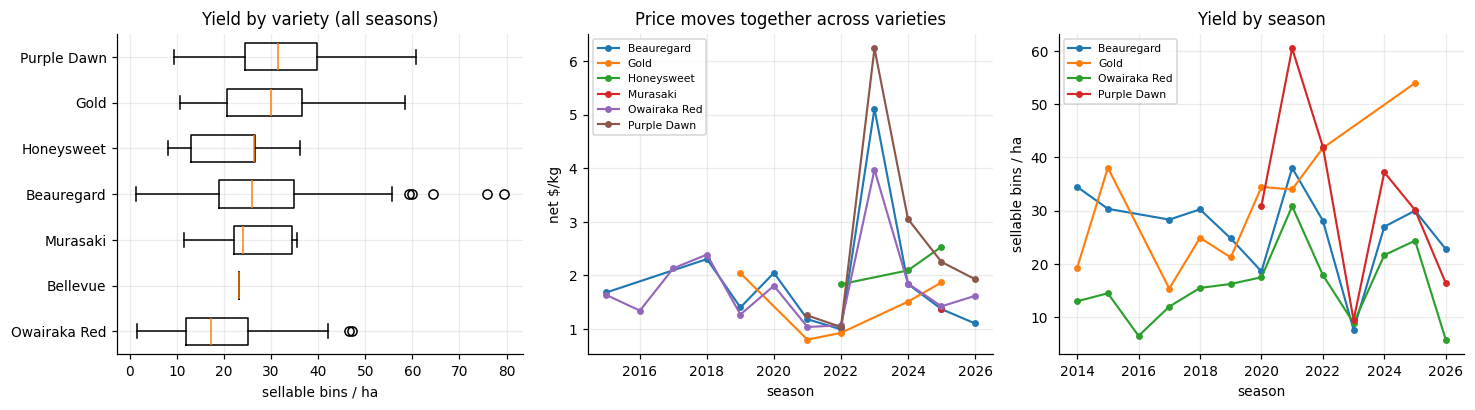

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

order = yield_df.groupby("variety").bins_per_ha.median().sort_values().index
axes[0].boxplot([yield_df.loc[yield_df.variety == v, "bins_per_ha"] for v in order],
                vert=False, labels=order, widths=0.6)
axes[0].set_xlabel("sellable bins / ha"); axes[0].set_title("Yield by variety (all seasons)")

for v, s in price_df.groupby("variety"):
    m = s.groupby("season").price.median()
    axes[1].plot(m.index, m.values, marker="o", ms=3.5, lw=1.4, label=v)
axes[1].set_xlabel("season"); axes[1].set_ylabel("net $/kg")
axes[1].set_title("Price moves together across varieties"); axes[1].legend(fontsize=7)

for v, s in yield_df.groupby("variety"):
    if len(s) < 8:
        continue
    m = s.groupby("season").bins_per_ha.median()
    axes[2].plot(m.index, m.values, marker="o", ms=3.5, lw=1.4, label=v)
axes[2].set_xlabel("season"); axes[2].set_ylabel("sellable bins / ha")
axes[2].set_title("Yield by season"); axes[2].legend(fontsize=7)

plt.tight_layout(); plt.show()

### 3.3 What a higher Premium share is worth

You expect Bellevue to grade out better than Beauregard (more Premium, because it resists scurf),
with every grade paid the same. The detail sheets put a price on that. On each delivery, compare
the Premium rate with the average rate of the other paid grades: moving one percentage point of the
crop into Premium adds that gap × 1% to the $/kg. The gap is expressed as a share of the net
price, so it scales with a dear or a cheap year.

The table also shows why Beauregard's price has slipped: its median Premium share fell from 41% in
2022 to 9% in 2026.

In [7]:
_d = pd.read_csv(PACKOUT_DIR / "all_years_detail.csv")
for c in ["kgs", "dollar_per_kg"]:
    _d[c] = pd.to_numeric(_d[c], errors="coerce")
_d["variety"] = _d.variety.map(PACKOUT_TO_COMMON).fillna(_d.variety)
_d["grade"] = _d.grade_raw.astype(str).str.lower().str.strip()
_d = _d[~_d.grade.str.startswith("waste")]
_d["rate"] = _d.dollar_per_kg.where(_d.dollar_per_kg.between(0.2, 10.0))  # OCR guard
_d = _d[(_d.kgs > 0) & _d.rate.notna()]
_d["premium"] = _d.grade.str.startswith("premium")

_kp = ["year_folder", "source_file", "source_page", "variety"]
_rows = []
for key, g in _d.groupby(_kp):
    if not g.premium.any() or g.premium.all():
        continue
    _rows.append(dict(zip(_kp, key),
                      premium_share=g.loc[g.premium, "kgs"].sum() / g.kgs.sum(),
                      premium_rate=np.average(g.loc[g.premium, "rate"], weights=g.loc[g.premium, "kgs"]),
                      other_rate=np.average(g.loc[~g.premium, "rate"], weights=g.loc[~g.premium, "kgs"])))
GRADES = pd.DataFrame(_rows).merge(
    pack[["year_folder", "source_file", "source_page", "price_computed"]],
    on=["year_folder", "source_file", "source_page"], how="inner")
GRADES = GRADES[GRADES.price_computed.between(*PRICE_RANGE)]
GRADES["gap_share"] = (GRADES.premium_rate - GRADES.other_rate) / GRADES.price_computed

# price uplift per +1 point of Premium share, as a fraction of net $/kg
PREMIUM_GAP = GRADES.groupby("variety").gap_share.median().to_dict()
print("each extra percentage point of the crop in Premium adds to net $/kg:")
for v, g in sorted(PREMIUM_GAP.items()):
    n = int((GRADES.variety == v).sum())
    print(f"  {v:<13} {g / 100:.2%} per point   ({n} deliveries)")

for v, b in NEW_VARIETY_BELIEFS.items():
    uplift = b["premium_pp"] / 100 * PREMIUM_GAP[b["like"]]
    print(f"\n{v}: +{b['premium_pp']:.0f} +/- {b['premium_pp_sd']:.0f} points of Premium "
          f"-> about {uplift:+.1%} on {b['like']}'s net $/kg")

show = [v for v in ["Beauregard", "Owairaka Red", "Purple Dawn"] if v in set(GRADES.variety)]
display(GRADES[GRADES.variety.isin(show)]
        .pivot_table(index="year_folder", columns="variety", values="premium_share",
                     aggfunc="median").round(2)
        .rename_axis("season (median share graded Premium)")
        .apply(lambda col: col.map(lambda x: "-" if pd.isna(x) else f"{x:.0%}")))

each extra percentage point of the crop in Premium adds to net $/kg:
  Beauregard    0.82% per point   (120 deliveries)
  Gold          0.78% per point   (7 deliveries)
  Honeysweet    0.32% per point   (1 deliveries)
  Murasaki      0.52% per point   (1 deliveries)
  Owairaka Red  0.71% per point   (247 deliveries)
  Purple Dawn   0.44% per point   (16 deliveries)

Bellevue: +10 +/- 5 points of Premium -> about +8.2% on Beauregard's net $/kg


variety,Beauregard,Owairaka Red,Purple Dawn
season (median share graded Premium),,,
2015,53%,44%,-
2016,-,45%,-
2017,-,18%,-
2018,42%,30%,-
2019,29%,23%,-
2020,20%,32%,-
2021,52%,48%,44%
2022,41%,32%,53%
2023,24%,7%,28%


## 4. Growing-season rainfall

Rainfall moves **yield** in your paddocks. Because the Kaipara grows most of New Zealand's kumara,
it also moves the **national crop** and so the **price**. Bringing it in replaces an anonymous
season effect with something you can forecast against.

Seasons are labelled by harvest year and run **1 October to 31 May**: season 2026 is October 2025
to May 2026. Rain at different points in that window does different things, so there are three
ways of slicing it:

| scheme | windows | the idea |
|---|---|---|
| `season` | Oct–May | one number: all the water the crop saw |
| `split` | Oct–Jan, Feb–May | establishment vs harvest-and-storage |
| `three` | **Oct–Dec**, **Jan–Feb**, **Mar–May** | rain that limits **planting**, rain that affects **growth**, rain that limits **harvest** and drives **storage rot** |

Section 4.1 compares them and 4.2 explains the choice.

The source is ERA5 reanalysis at a grid point near Ruawai (Dargaville correlates with it at
0.988). It is a modelled reconstruction, not your rain gauge; see `Rainfall_Data/README.md`.

In [8]:
# Which calendar months belong to each window, for each scheme.
RAIN_SCHEMES = {
    "season": {"total":   [10, 11, 12, 1, 2, 3, 4, 5]},
    "split":  {"early":   [10, 11, 12, 1],
               "late":    [2, 3, 4, 5]},
    "three":  {"plant":   [10, 11, 12],     # wet here and you cannot get the crop in
               "grow":    [1, 2],           # bulking
               "harvest": [3, 4, 5]},       # lifting, and rot in store
}
ALL_MONTHS = [10, 11, 12, 1, 2, 3, 4, 5]

monthly_path = RAINFALL_DIR / "monthly_rainfall.csv"
HAVE_MONTHLY = monthly_path.exists()

if HAVE_MONTHLY:
    mon = pd.read_csv(monthly_path)
    mon = mon[mon.site == RAIN_SITE].copy()
    piv = mon.pivot_table(index="season", columns="month", values="rain_mm", aggfunc="sum")
    piv = piv.reindex(columns=ALL_MONTHS)
    piv = piv[piv.notna().all(axis=1)]                  # complete 8-month record only
    rain_df = pd.DataFrame(index=piv.index)
    for scheme, wins in RAIN_SCHEMES.items():
        for name, months in wins.items():
            rain_df[name] = piv[months].sum(axis=1)
    MONTHLY = piv
else:
    sr = pd.read_csv(RAINFALL_DIR / "season_rainfall.csv")
    rain_df = (sr[sr.site == RAIN_SITE].set_index("season")[["rain_oct_may_mm"]]
                 .rename(columns={"rain_oct_may_mm": "total"}))
    for c in ["early", "late", "plant", "grow", "harvest"]:
        rain_df[c] = np.nan
    MONTHLY = None
    print("monthly_rainfall.csv not found - season totals only; "
          "any model asking for windows will fall back to 'season'")

rain_df = rain_df.sort_index()
rain = rain_df["total"]          # headline series, used by scenarios and plots

print(f"{RAIN_SITE}: {len(rain_df)} seasons, {rain.index.min()}-{rain.index.max()}")
print(f"  total  driest {rain.min():.0f} mm ({rain.idxmin()})   median {rain.median():.0f}   "
      f"wettest {rain.max():.0f} mm ({rain.idxmax()})")
if HAVE_MONTHLY:
    for nm in ["plant", "grow", "harvest"]:
        s = rain_df[nm]
        print(f"  {nm:<8} median {s.median():5.0f} mm   range {s.min():.0f}-{s.max():.0f}   "
              f"typically {100*(s/rain_df.total).median():.0f}% of the season")
display(rain_df[["plant", "grow", "harvest", "total"]].round(0)
        if HAVE_MONTHLY else rain_df.round(0))

Ruawai: 13 seasons, 2014-2026
  total  driest 341 mm (2014)   median 604   wettest 1272 mm (2023)
  plant    median   229 mm   range 142-488   typically 39% of the season
  grow     median   112 mm   range 35-431   typically 18% of the season
  harvest  median   245 mm   range 113-362   typically 37% of the season


,plant,grow,harvest,total
season,,,,
2014,168.0,60.0,113.0,341.0
2015,229.0,76.0,251.0,556.0
2016,142.0,216.0,182.0,540.0
2017,199.0,112.0,294.0,604.0
2018,155.0,213.0,312.0,679.0
2019,340.0,80.0,161.0,582.0
2020,224.0,35.0,225.0,484.0
2021,181.0,132.0,215.0,528.0
2022,357.0,111.0,245.0,713.0


In [9]:
# ---- standardisation and design columns, shared by every model and scenario
RAIN_COLS = {k: list(v) for k, v in RAIN_SCHEMES.items()}
RAIN_Z = {c: (float(rain_df[c].mean()), float(rain_df[c].std()))
          for c in rain_df.columns if rain_df[c].notna().any()}

if not HAVE_MONTHLY:
    RAIN_WINDOWS = {k: "season" for k in RAIN_WINDOWS}


def rain_terms(form, windows):
    "Names of the design columns for a (form, windows) combination."
    out = []
    for c in RAIN_COLS[windows]:
        out.append(f"{c}>{RAIN_HINGE_MM[c]:.0f}" if form == "hinge" else c)
        if form == "quadratic":
            out.append(c + "_sq")
    return out


def rain_features(mm, form, windows):
    "Design columns. mm: (n,) for a single window, or (n, k) matching RAIN_COLS[windows]."
    A = np.asarray(mm, dtype=float)
    if A.ndim == 1:
        A = A[:, None]
    cols = RAIN_COLS[windows]
    if A.shape[1] != len(cols):
        raise ValueError(f"windows='{windows}' expects {len(cols)} column(s), got {A.shape[1]}")
    out = []
    for j, c in enumerate(cols):
        if form == "hinge":
            # mm above the threshold in units of 100 mm, so the coefficient reads as
            # "log change per extra 100 mm once it is already too wet"
            out.append(np.maximum(0.0, A[:, j] - RAIN_HINGE_MM[c]) / 100.0)
            continue
        mu, sd = RAIN_Z[c]
        zc = (A[:, j] - mu) / sd
        out.append(zc)
        if form == "quadratic":
            out.append(zc ** 2)
    return np.column_stack(out)


def rain_total_z(total_mm):
    "Standardised season total - basis for the variety interaction, whatever the windows."
    mu, sd = RAIN_Z["total"]
    return (np.asarray(total_mm, dtype=float) - mu) / sd


# Each historical season gives a SHAPE: how its rain divided between the windows.
# Scenarios borrow a whole shape rather than an average one, because the windows do
# not move together and averaging them would quietly cancel out offsetting effects.
RAIN_SHARES = {s: rain_df[RAIN_COLS[s]].div(rain_df.total, axis=0) for s in RAIN_SCHEMES}
N_SHAPES = len(rain_df)


def mm_for(windows, total_mm, shape_idx):
    "A season total plus a borrowed shape -> that model's per-window rainfall input."
    total_mm = np.asarray(total_mm, dtype=float)
    sh = RAIN_SHARES[windows].to_numpy()[np.asarray(shape_idx, dtype=int)]
    return total_mm[:, None] * sh


for k in ("yield", "price"):
    print(f"{k:>6}: windows '{RAIN_WINDOWS[k]}', form '{RAIN_FORM[k]}' "
          f"-> terms {rain_terms(RAIN_FORM[k], RAIN_WINDOWS[k])}")

 yield: windows 'three', form 'linear' -> terms ['plant', 'grow', 'harvest']
 price: windows 'split', form 'linear' -> terms ['early', 'late']


### 4.1 Does rainfall track the season-to-season swings?

A model-free check before building rainfall in. Remove variety (and site, for yield) with a plain
least-squares fit, average the residuals within each season to get a rough "how good was that
season" number, and regress that on each rainfall scheme. The second table repeats the test with
2023 dropped.

Yield here is per hectare **lifted**, so this tests how rain moves yield on the paddocks you *do*
get into. Lost paddocks are handled in section 8.1.

In [10]:
def season_residual_effects(df, value_col, cols=("variety",)):
    "Season means of residuals after removing variety (and site) by OLS - model-free."
    X = pd.get_dummies(df[list(cols)].astype(str), drop_first=True).astype(float)
    X.insert(0, "const", 1.0)
    Xv, yv = X.to_numpy(), df[value_col].to_numpy()
    beta, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
    resid = pd.Series(yv - Xv @ beta, index=pd.Index(df.season.to_numpy(), name="season"))
    return resid.groupby(level=0).mean()


def shape_fit(effects, form, windows, drop_season=None):
    "OLS of season effects on a rainfall spec; coefficients and adjusted R2."
    cols = RAIN_COLS[windows]
    idx = [s for s in effects.index
           if s in rain_df.index and rain_df.loc[s, cols].notna().all() and s != drop_season]
    e = effects.loc[idx].to_numpy()
    X = np.column_stack([np.ones(len(idx)),
                         rain_features(rain_df.loc[idx, cols].to_numpy(), form, windows)])
    beta, *_ = np.linalg.lstsq(X, e, rcond=None)
    ss_res = ((e - X @ beta) ** 2).sum()
    ss_tot = ((e - e.mean()) ** 2).sum()
    n, k = len(idx), X.shape[1]
    r2 = 1 - ss_res / ss_tot
    return dict(beta=beta, r2=r2, adj_r2=1 - (1 - r2) * (n - 1) / (n - k), n=n, cols=cols)


EFF = {
    "yield": season_residual_effects(yield_df, "log_yield", ("variety", "site")),
    "price": season_residual_effects(price_df, "log_price", ("variety",)),
}

SPECS = [("season", "linear"), ("season", "hinge")]
if HAVE_MONTHLY:
    SPECS += [("split", "linear"), ("three", "linear"), ("three", "hinge")]

rows = []
for nm, eff in EFF.items():
    r = {"model": nm}
    for win, form in SPECS:
        r[f"{win} {form}"] = round(shape_fit(eff, form, win)["adj_r2"], 3)
        r[f"{win} {form} (no 2023)"] = round(
            shape_fit(eff, form, win, drop_season=2023)["adj_r2"], 3)
    rows.append(r)
tabspec = pd.DataFrame(rows).set_index("model")
print("Adjusted R2 by specification. The '(no 2023)' columns are the robustness test:")
display(tabspec[[c for c in tabspec.columns if "no 2023" not in c]])
display(tabspec[[c for c in tabspec.columns if "no 2023" in c]])

Adjusted R2 by specification. The '(no 2023)' columns are the robustness test:


,season linear,season hinge,split linear,three linear,three hinge
model,,,,,
yield,0.169,0.339,0.092,0.463,0.144
price,0.211,0.417,0.514,0.151,0.607


,season linear (no 2023),season hinge (no 2023),split linear (no 2023),three linear (no 2023),three hinge (no 2023)
model,,,,,
yield,-0.092,0.094,-0.191,0.195,-0.283
price,-0.030,-0.052,0.325,0.205,0.077


### 4.2 What the three windows say

The three-window scheme fits yield best (adjusted R² 0.46), and its coefficients match the
agronomy:

| window | coefficient | reading |
|---|---|---|
| **plant** (Oct–Dec) | ≈ 0 | planting rain limits how much you get *in*, not what each hectare yields |
| **grow** (Jan–Feb) | **negative** | the main yield driver on lifted paddocks: waterlogging during bulking |
| **harvest** (Mar–May) | small, positive | harvest rain does its damage by stopping paddocks being lifted, and this model only sees lifted paddocks |

So each mechanism is handled in exactly one place:

> **Jan–Feb rain → lower yield on what you lift →** `beta_rain[grow]` in the yield model
> **A very wet season → paddocks abandoned →** the abandonment curve, section 8.1
> **Oct–Dec rain → less area planted →** not modelled; see below

**Why abandonment follows the season total, not March–May.** 2025 had the wettest March–May on
record (362 mm) and lost nothing; 2023 (353 mm) lost 40% of the farm. What set 2023 apart was the
whole season: 488 mm before Christmas, Cyclone Gabrielle's 264 mm in February, and ground that never
dried out. Set `HARVEST_LOSS["driver"]` to `"harvest"` if you disagree.

**What is not modelled.** Planted area is taken as given (`TOTAL_AREA_HA`). A wet spring that costs
you three hectares of planting is a real loss the model does not price. If that is a live risk,
treat `TOTAL_AREA_HA` itself as uncertain.

**Price uses the two-way split.** Price responds to Feb–May as a block, and with only twelve priced
seasons, finer windows cost more in precision than they gain. The split also holds up best when
2023 is dropped (adjusted R² 0.33, against 0.21 for three windows).

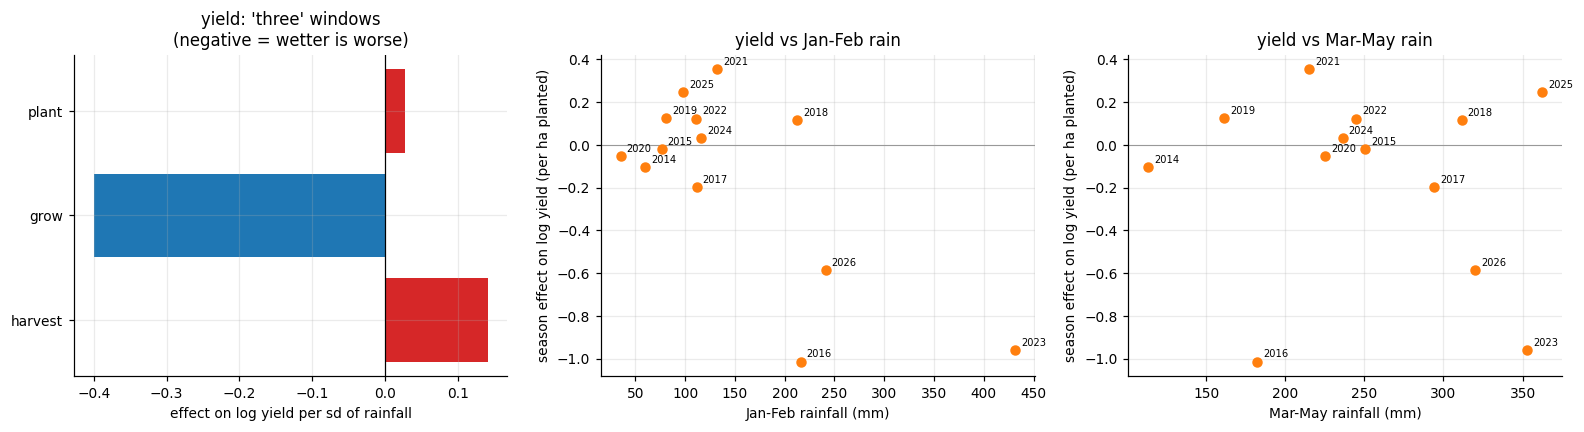

yield window coefficients: plant +0.027  grow -0.400  harvest +0.141
price window coefficients: early -0.114  late +0.385


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0))

# --- per-window coefficients for the chosen yield spec
nm = "yield"
f = shape_fit(EFF[nm], RAIN_FORM[nm], RAIN_WINDOWS[nm])
cols = f["cols"]
axes[0].barh(range(len(cols)), f["beta"][1:], color=["C0" if b < 0 else "C3" for b in f["beta"][1:]])
axes[0].set_yticks(range(len(cols))); axes[0].set_yticklabels(cols)
axes[0].axvline(0, color="k", lw=0.8); axes[0].invert_yaxis()
axes[0].set_xlabel("effect on log yield per sd of rainfall")
axes[0].set_title(f"yield: '{RAIN_WINDOWS[nm]}' windows\n(negative = wetter is worse)")

# --- each window against the season effect
if HAVE_MONTHLY:
    for ax, win in zip(axes[1:], ["grow", "harvest"]):
        e = EFF["yield"]
        idx = [s for s in e.index if s in rain_df.index]
        ax.scatter(rain_df.loc[idx, win], e.loc[idx], s=34, color="C1", zorder=5)
        for s in idx:
            ax.annotate(str(s), (rain_df.loc[s, win], e.loc[s]), fontsize=6.5,
                        xytext=(4, 3), textcoords="offset points")
        ax.axhline(0, color="0.6", lw=0.7)
        lbl = {"grow": "Jan-Feb", "harvest": "Mar-May"}[win]
        ax.set_xlabel(f"{lbl} rainfall (mm)")
        ax.set_ylabel("season effect on log yield (per ha lifted)")
        ax.set_title(f"yield vs {lbl} rain")

plt.tight_layout(); plt.show()

f = shape_fit(EFF["yield"], RAIN_FORM["yield"], RAIN_WINDOWS["yield"])
print("yield window coefficients: " +
      "  ".join(f"{c} {b:+.3f}" for c, b in zip(f["cols"], f["beta"][1:])))
fp = shape_fit(EFF["price"], RAIN_FORM["price"], RAIN_WINDOWS["price"])
print("price window coefficients: " +
      "  ".join(f"{c} {b:+.3f}" for c, b in zip(fp["cols"], fp["beta"][1:])))

### 4.3 How much of this is still 2023?

Cyclone Gabrielle's season (1272 mm, 264 mm of it in February) was the worst on record for yield and
the best for price. The "(no 2023)" table in section 4.1 refits without it. The three-window yield
scheme holds up best: adjusted R² 0.20 without 2023, where the season-total schemes fall to 0.09 or
below. Splitting the season lets the fit pin 2023's damage on the window that caused it.

Two limits remain that better modelling cannot fix:

- **The wet end rests on two seasons**, 2023 and 2026.
- **The dry end has almost no evidence.** Only 2014 (341 mm) and 2020 (484 mm) fall below 500 mm,
  and the linear Jan–Feb term implies that less rain always means more yield, which cannot hold in
  a real drought. **If your drought runs dry through January and February, expect the model to be
  optimistic about yield** (caveat 12).

## 5. The hierarchical model

All three quantities are positive and roughly multiplicative, so each is modelled on the log scale
with the same core:

$$\log y_i \sim \text{StudentT}\!\left(\nu,\; \mu + \alpha_{v[i]} + \beta_{t[i]} + \gamma_{s[i]} + \delta_{v[i],s[i]},\; \sigma_i\right)$$

$$\beta_t = \mathbf x_t^\top \boldsymbol\beta_{\text{rain}} + u_t, \qquad
\alpha_v \sim \mathcal N(0, \sigma_\alpha), \quad u_t \sim \mathcal N(0, \sigma_u), \quad
\gamma_s \sim \mathcal N(0, \sigma_\gamma), \quad \delta_{v,s} \sim \mathcal N(0, \sigma_{\delta})$$

- **$\sigma_\alpha$ is learned.** It sets how hard thin varieties are shrunk: it is large if
  varieties genuinely differ, and near zero if the differences look like noise.
- **The season effect $\beta_t$ is shared across varieties**, so a bad year is charged to the year,
  not to whichever variety was planted. It splits into what the rainfall windows $\mathbf x_t$
  explain and a residual $u_t$. $\sigma_u$ is the season volatility a forecast must still carry. A
  small variety-specific rainfall slope (section 7.1) lets varieties take a wet or dry year
  differently.
- **Yield only: site $\gamma_s$ and variety × site $\delta_{v,s}$**, partially pooled (section 5.3).
- **Yield only: area-weighted noise**, $\sigma_i^2 = \sigma_{\text{paddock}}^2 + \sigma_{\text{area}}^2/\text{ha}_i$.
  Part of a paddock's deviation does not shrink with size (soil, timing, drainage); part is
  within-paddock noise, which does. A 0.1 ha strip counts for much less than a 2 ha paddock.
- **Price only: premium drift.** Each variety's premium is a random walk anchored at the latest
  season, so $\alpha_v$ is the premium *now*. The step size $\sigma_{\text{drift}}$ is learned
  (zero would mean a fixed premium), and the forecast adds one more step.
- **StudentT, not Normal**, with $\nu$ estimated, so outliers (OCR slips, odd paddocks) are
  discounted rather than dragging a variety's mean.
- **Non-centred parameterisation** ($\alpha = z\sigma_\alpha$, $z\sim\mathcal N(0,1)$), the
  standard fix for the funnel geometry that makes these models sample badly.

Priors are weakly informative on the log scale: $\mu$ is centred on the observed grand mean with
sd 1, and the half-normal scales (sd 0.5 by default) allow effects of roughly ±50%.

In [12]:
def fit_hierarchical(df, value_col, name, use_site=False, scale_prior=0.5,
                     use_rain=False, rain_interaction=False, rain_form="quadratic",
                     rain_windows="season", area_col=None, variety_site=False,
                     variety_drift=False, sample_kw=None):
    "Fit log-scale StudentT model with variety + season (+ site, + rainfall) effects."
    d = df.dropna(subset=[value_col]).copy()
    if use_rain:                      # keep only seasons with usable rainfall
        ok_seasons = rain_df.index[rain_df[RAIN_COLS[rain_windows]].notna().all(axis=1)]
        d = d[d.season.isin(ok_seasons)].copy()
    varieties = sorted(d.variety.unique())
    seasons   = sorted(d.season.unique())
    v_idx = pd.Categorical(d.variety, categories=varieties).codes
    s_idx = pd.Categorical(d.season,  categories=seasons).codes

    coords = {"variety": varieties, "season": seasons}
    if variety_drift:
        coords["season_step"] = seasons[:-1]
    sites = []
    if use_site:
        sites = sorted(d.site.fillna("unknown").unique())
        g_idx = pd.Categorical(d.site.fillna("unknown"), categories=sites).codes
        coords["site"] = sites
    if use_rain:
        # one row per season, in the same order as the season coord
        R = rain_features(rain_df.loc[seasons, RAIN_COLS[rain_windows]].to_numpy(),
                          rain_form, rain_windows)
        R_TOT = rain_total_z(rain_df.loc[seasons, "total"].to_numpy())   # for the interaction
        coords["rain_term"] = rain_terms(rain_form, rain_windows)

    y = d[value_col].to_numpy()
    grand = float(np.mean(y))
    if area_col:
        A_obs = d[area_col].to_numpy(dtype=float)

    with pm.Model(coords=coords) as model:
        mu = pm.Normal("mu", grand, 1.0)

        sigma_variety = pm.HalfNormal("sigma_variety", scale_prior)
        z_v = pm.Normal("z_variety", 0.0, 1.0, dims="variety")
        a_variety = pm.Deterministic("a_variety", z_v * sigma_variety, dims="variety")

        # The season effect splits into a part rainfall explains and a part it does not.
        # sigma_season is now the size of a season shock AFTER accounting for rainfall,
        # which is what we must carry into a forecast on top of a rainfall scenario.
        sigma_season = pm.HalfNormal("sigma_season", scale_prior)
        z_s = pm.Normal("z_season", 0.0, 1.0, dims="season")
        u_season = pm.Deterministic("u_season", z_s * sigma_season, dims="season")

        if use_rain:
            beta_rain = pm.Normal("beta_rain", 0.0, 0.5, dims="rain_term")
            rain_eff = pm.Deterministic("rain_effect", pm.math.dot(R, beta_rain),
                                        dims="season")
            b_season = pm.Deterministic("b_season", rain_eff + u_season, dims="season")
        else:
            b_season = pm.Deterministic("b_season", u_season, dims="season")

        eta = mu + a_variety[v_idx] + b_season[s_idx]

        if variety_drift:
            # Each variety's premium drifts season to season as a random walk, anchored at
            # the LATEST season: a_variety is the premium now, and the walk runs backwards
            # through history. Old seasons still count, but less the further back they are.
            sigma_drift = pm.HalfNormal("sigma_drift", 0.15)
            z_d = pm.Normal("z_drift", 0.0, 1.0, dims=("variety", "season_step"))
            steps = z_d * sigma_drift
            back = pt.cumsum(steps[:, ::-1], axis=1)[:, ::-1]      # sum of steps t..T-1
            drift = pm.Deterministic(
                "drift_variety",
                pt.concatenate([back, pt.zeros((len(varieties), 1))], axis=1),
                dims=("variety", "season"))
            eta = eta + drift[v_idx, s_idx]

        if use_rain and rain_interaction:
            # Do varieties respond to rainfall differently? Partially pooled, so if the
            # data carry no such evidence sigma_rain_variety collapses and every variety
            # gets the common slope. Only the linear term is interacted - a per-variety
            # curvature is hopeless with this many seasons.
            sigma_rain_variety = pm.HalfNormal("sigma_rain_variety", 0.15)
            z_rv = pm.Normal("z_rain_variety", 0.0, 1.0, dims="variety")
            d_rain = pm.Deterministic("delta_rain_variety", z_rv * sigma_rain_variety,
                                      dims="variety")
            # interaction is on the season TOTAL whatever the windows, so it always
            # answers the same question: do varieties differ in overall drought tolerance?
            eta = eta + d_rain[v_idx] * R_TOT[s_idx]

        if use_site:
            sigma_site = pm.HalfNormal("sigma_site", 0.3)
            z_g = pm.Normal("z_site", 0.0, 1.0, dims="site")
            c_site = pm.Deterministic("c_site", z_g * sigma_site, dims="site")
            eta = eta + c_site[g_idx]

            if variety_site:
                # Does a variety's advantage depend on the site? Partially pooled: with no
                # evidence sigma_variety_site collapses and every variety keeps its farm-wide
                # effect everywhere, and thin variety x site cells are shrunk hard to zero.
                sigma_vs = pm.HalfNormal("sigma_variety_site", 0.2)
                z_vs = pm.Normal("z_variety_site", 0.0, 1.0, dims=("variety", "site"))
                d_vs = pm.Deterministic("d_variety_site", z_vs * sigma_vs,
                                        dims=("variety", "site"))
                eta = eta + d_vs[v_idx, g_idx]

        sigma_obs = pm.HalfNormal("sigma_obs", 1.0)
        if area_col:
            # Area-weighted noise. Part of a paddock's deviation is paddock-level (soil,
            # timing, drainage) and does not shrink with size; part is within-paddock
            # sampling noise, which shrinks as 1/sqrt(ha). A 0.1 ha strip therefore gets a
            # much wider likelihood than a 2 ha paddock, and pulls the estimates far less.
            sigma_area = pm.HalfNormal("sigma_area", 0.5)
            sig = pm.math.sqrt(sigma_obs ** 2 + sigma_area ** 2 / A_obs)
        else:
            sig = sigma_obs
        nu = pm.Gamma("nu", alpha=2.0, beta=0.1)
        pm.StudentT("obs", nu=nu, mu=eta, sigma=sig, observed=y)

        idata = pm.sample(**(sample_kw or SAMPLE_KW))
        pp = pm.sample_posterior_predictive(idata, random_seed=1, progressbar=False)
        idata["posterior_predictive"] = pp["posterior_predictive"]

    idata.attrs["levels_variety"] = varieties
    idata.attrs["levels_season"]  = [int(s) for s in seasons]
    idata.attrs["levels_site"]    = sites
    idata.attrs["n_obs"]          = len(d)
    idata.attrs["use_rain"]       = bool(use_rain)
    idata.attrs["rain_interaction"] = bool(use_rain and rain_interaction)
    idata.attrs["rain_form"]      = rain_form if use_rain else None
    idata.attrs["rain_windows"]   = rain_windows if use_rain else None
    idata.attrs["rain_terms"]     = (rain_terms(rain_form, rain_windows)
                                     if use_rain else [])
    idata.attrs["area_weighted"]  = bool(area_col)
    idata.attrs["variety_site"]   = bool(use_site and variety_site)
    idata.attrs["variety_drift"]  = bool(variety_drift)
    print(f"[{name}] {len(d)} obs | {len(varieties)} varieties | {len(seasons)} seasons"
          + (f" | {len(sites)} sites" if use_site else "")
          + (" | variety x site" if use_site and variety_site else "")
          + (" | area-weighted" if area_col else "")
          + (" | premium drift" if variety_drift else ""))
    return model, idata


def check(idata, name, extra=()):
    "Convergence diagnostics; loud if anything is off."
    v = ["mu", "sigma_variety", "sigma_season", "sigma_obs", "nu", *extra]
    if idata.attrs.get("use_rain"):
        v.insert(3, "beta_rain")
    if idata.attrs.get("rain_interaction"):
        v.insert(4, "sigma_rain_variety")
    s = az.summary(idata, var_names=v)
    # ArviZ 1.x returns display-formatted strings, so coerce before comparing
    num = s.apply(pd.to_numeric, errors="coerce")
    max_r, min_e = num.r_hat.max(), num.ess_bulk.min()
    div = idata["sample_stats"]["diverging"]
    n_div, n_draw = int(div.sum()), int(div.size)
    # a handful of divergences in thousands of draws is not a problem; a rate is
    ok = max_r <= 1.01 and min_e >= 400 and n_div / n_draw < 0.005
    print(f"[{name}] {'OK' if ok else 'CHECK'}: max r_hat {max_r:.3f}, "
          f"min ess_bulk {int(min_e)}, {n_div}/{n_draw} divergent "
          f"({n_div/n_draw:.2%})")
    return s


def forest(ax, idata, var, labels, title, ref=0.0):
    "Median with 50% and 90% intervals, one row per level."
    d = np.moveaxis(np.asarray(az.extract(idata, group="posterior")[var]), -1, 0)
    lo90, lo50, med, hi50, hi90 = np.quantile(d, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0)
    yy = np.arange(len(labels))
    ax.hlines(yy, lo90, hi90, color="C0", lw=1.2)
    ax.hlines(yy, lo50, hi50, color="C0", lw=4.0, alpha=0.85)
    ax.plot(med, yy, "o", color="k", ms=4, zorder=5)
    if ref is not None:
        ax.axvline(ref, color="0.4", lw=0.8, ls="--")
    ax.set_yticks(yy); ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis(); ax.set_title(title)

### 5.1 Model A — yield (sellable bins per hectare)

Fitted on yield per hectare lifted, with site and variety × site effects. The two sites do not
yield alike and varieties are unevenly spread across them, so leaving site out would let a site
difference pass for a variety difference. Noise is area-weighted (section 5).

In [13]:
model_yield, idata_yield = fit_hierarchical(
    yield_df, "log_yield", "yield", use_site=True,
    use_rain=USE_RAINFALL, rain_interaction=RAIN_VARIETY_INTERACTION,
    rain_form=RAIN_FORM['yield'], rain_windows=RAIN_WINDOWS['yield'],
    area_col="area_ha", variety_site=VARIETY_SITE_INTERACTION)
display(check(idata_yield, "yield",
              extra=["sigma_site", "sigma_area"]
                    + (["sigma_variety_site"] if VARIETY_SITE_INTERACTION else [])))

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu, sigma_variety, z_variety, sigma_season, z_season, beta_rain, sigma_rain_variety, z_rain_variety, sigma_site, z_site, sigma_variety_site, z_variety_site, sigma_obs, sigma_area, nu]


Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 291 seconds.


Sampling: [obs]


[yield] 324 obs | 7 varieties | 13 seasons | 2 sites | variety x site | area-weighted


[yield] OK: max r_hat 1.000, min ess_bulk 2531, 0/6000 divergent (0.00%)


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,3.092,0.268,2.7,3.5,4390,3799,1.00,0.0041,0.0035
sigma_variety,0.246,0.116,0.096,0.45,2587,2792,1.00,0.0021,0.0025
sigma_season,0.322,0.096,0.2,0.49,2963,3893,1.00,0.0018,0.0022
beta_rain[plant],-0.069,0.122,-0.26,0.13,4001,3836,1.00,0.0019,0.0016
beta_rain[grow],-0.308,0.136,-0.53,-0.098,4111,4218,1.00,0.0021,0.0018
beta_rain[harvest],0.071,0.121,-0.12,0.27,3477,3419,1.00,0.0021,0.0017
sigma_rain_variety,0.063,0.052,0.0055,0.16,4332,3312,1.00,0.0007,0.00075
sigma_obs,0.2932,0.0358,0.24,0.35,5868,4363,1.00,0.00047,0.00035
nu,3.68,0.95,2.5,5.4,8056,4927,1.00,0.012,0.014
sigma_site,0.296,0.148,0.11,0.56,4336,3223,1.00,0.002,0.0018


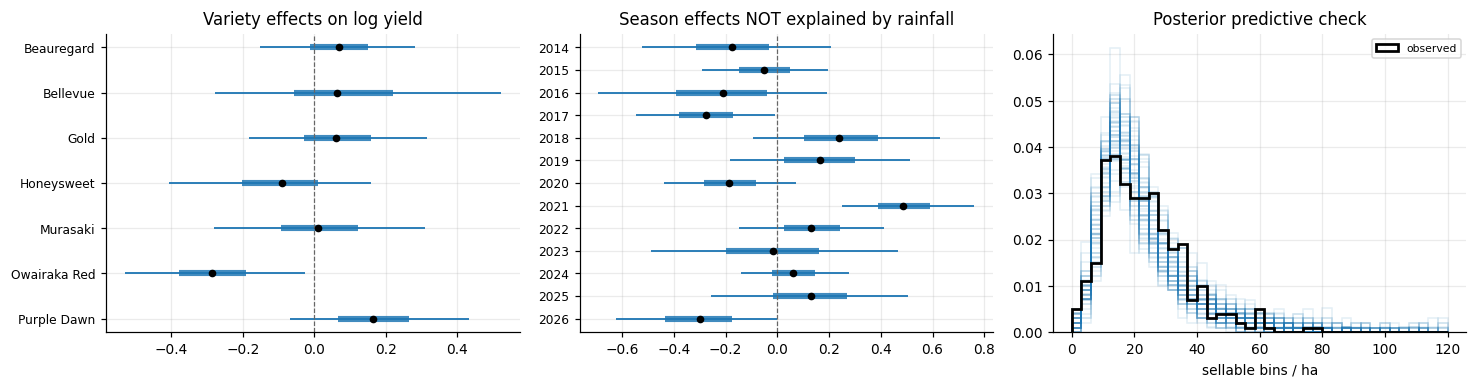

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))

forest(axes[0], idata_yield, "a_variety", idata_yield.attrs["levels_variety"],
       "Variety effects on log yield")
forest(axes[1], idata_yield, "u_season", idata_yield.attrs["levels_season"],
       "Season effects NOT explained by rainfall" if USE_RAINFALL else "Season effects")

# posterior predictive check on the observed scale
obs = np.exp(yield_df.log_yield.to_numpy())
ppc = np.exp(np.asarray(idata_yield["posterior_predictive"]["obs"]).reshape(-1, len(obs)))
for i in RNG.choice(ppc.shape[0], 60, replace=False):
    axes[2].hist(ppc[i], bins=np.linspace(0, 120, 40), histtype="step",
                 density=True, color="C0", alpha=0.12)
axes[2].hist(obs, bins=np.linspace(0, 120, 40), histtype="step",
             density=True, color="k", lw=1.8, label="observed")
axes[2].set_xlabel("sellable bins / ha"); axes[2].set_title("Posterior predictive check")
axes[2].legend(fontsize=7)

plt.tight_layout(); plt.show()

### 5.2 How much is the model shrinking the thin varieties?

Raw per-variety geometric means against the model's posterior means. Well-recorded varieties barely
move; thin ones are pulled toward the farm-wide average, by an amount set by $\sigma_\alpha$, which
is itself estimated from the data.

In [15]:
lv = idata_yield.attrs["levels_variety"]
post_v = az.extract(idata_yield, group="posterior")
mu_y = np.asarray(post_v["mu"])
a_y  = np.asarray(post_v["a_variety"])          # (variety, draw)
model_mean = np.exp(mu_y[None, :] + a_y).mean(axis=1)

# compare like with like: the model is fitted on logs, so the raw comparator is
# the geometric mean, not the arithmetic one
raw = (yield_df.groupby("variety").log_yield.agg(["mean", "size"]).reindex(lv)
       .assign(geo=lambda d: np.exp(d["mean"])))
shrink = pd.DataFrame({"n_obs": raw["size"].astype(int),
                       "raw_geo_mean": raw["geo"].round(1),
                       "model_mean": np.round(model_mean, 1)}, index=lv)
shrink["pulled_by"] = (shrink.model_mean - shrink.raw_geo_mean).round(1)
display(shrink.sort_values("n_obs", ascending=False))

sig_a = float(np.asarray(post_v["sigma_variety"]).mean())
sig_b = float(np.asarray(post_v["sigma_season"]).mean())
print(f"sigma_variety = {sig_a:.2f}  ->  a typical variety sits about "
      f"{100*(np.exp(sig_a)-1):.0f}% above / {100*(1-np.exp(-sig_a)):.0f}% below the farm mean")
print(f"sigma_season  = {sig_b:.2f}  ->  a typical season swings yield by roughly "
      f"+{100*(np.exp(sig_b)-1):.0f}% / -{100*(1-np.exp(-sig_b)):.0f}%")

,n_obs,raw_geo_mean,model_mean,pulled_by
Owairaka Red,192,16.6,17.2,0.6
Beauregard,87,23.7,24.3,0.6
Gold,19,28.4,24.4,-4.0
Purple Dawn,15,29.0,27.1,-1.9
Murasaki,5,23.7,23.3,-0.4
Honeysweet,5,19.3,20.8,1.5
Bellevue,1,23.3,25.7,2.4


sigma_variety = 0.25  ->  a typical variety sits about 28% above / 22% below the farm mean
sigma_season  = 0.32  ->  a typical season swings yield by roughly +38% / -28%


### 5.3 Does a variety's performance depend on the site?

You are planting at Hodgson, so what matters is how each variety does *there*. Each variety's yield
effect may differ between Hodgson and Te Kowhai, partially pooled: a variety with plenty of paddocks
at both sites gets its own site difference, and one with only a couple is pulled toward the common
site effect. Without this term every variety would share the same site effect, which cancels out of
any comparison between them, so `PLAN_SITE` could move the profit but never the mix.

The table gives yield per hectare lifted in a typical season at each site, and the probability that
each variety does *relatively* better at Hodgson. `sigma_variety_site` measures how much the data
support site-specific differences.

In [16]:
if VARIETY_SITE_INTERACTION:
    pv = az.extract(idata_yield, group="posterior")
    lv = list(idata_yield.attrs["levels_variety"])
    ls = list(idata_yield.attrs["levels_site"])
    mu_, a_ = np.asarray(pv["mu"]), np.asarray(pv["a_variety"])          # (S,), (V, S)
    c_, d_ = np.asarray(pv["c_site"]), np.asarray(pv["d_variety_site"])  # (G, S), (V, G, S)
    gH = next(i for i, s in enumerate(ls) if site_short(s) == "Hodgson")
    gT = next(i for i, s in enumerate(ls) if site_short(s) == "Te Kowhai")
    n = yield_df.groupby(["variety", "site"]).size()

    rows = []
    for i, v in enumerate(lv):
        yH = np.exp(mu_ + a_[i] + c_[gH] + d_[i, gH])
        yT = np.exp(mu_ + a_[i] + c_[gT] + d_[i, gT])
        rows.append({"variety": v,
                     "Hodgson n": int(n.get((v, ls[gH]), 0)),
                     "Te Kowhai n": int(n.get((v, ls[gT]), 0)),
                     "Hodgson bins/ha": round(float(np.median(yH)), 1),
                     "Te Kowhai bins/ha": round(float(np.median(yT)), 1),
                     "P(relatively better at Hodgson)":
                         round(float((d_[i, gH] > d_[i, gT]).mean()), 2),
                     "candidate": v in CANDIDATES})
    display(pd.DataFrame(rows).set_index("variety"))

    svs = np.asarray(pv["sigma_variety_site"])
    print(f"sigma_variety_site = {svs.mean():.3f} [90% {np.quantile(svs, .05):.3f}, "
          f"{np.quantile(svs, .95):.3f}]   vs sigma_variety {float(np.asarray(pv['sigma_variety']).mean()):.3f}")
    print("  Values near 0.5 in the last column mean the data cannot tell; the model then")
    print("  keeps that variety's farm-wide ranking at both sites.")

,Hodgson n,Te Kowhai n,Hodgson bins/ha,Te Kowhai bins/ha,P(relatively better at Hodgson),candidate
variety,,,,,,
Beauregard,29,58,29.6,19.5,0.70,True
Bellevue,1,0,29.0,20.0,0.54,True
Gold,5,14,28.1,20.3,0.39,True
Honeysweet,2,3,23.6,16.5,0.50,False
Murasaki,4,1,26.6,19.0,0.46,True
Owairaka Red,58,134,19.7,13.0,0.71,True
Purple Dawn,8,7,32.1,22.6,0.48,True


sigma_variety_site = 0.088 [90% 0.006, 0.229]   vs sigma_variety 0.246
  Values near 0.5 in the last column mean the data cannot tell; the model then
  keeps that variety's farm-wide ranking at both sites.


## 6. Model B — bin weight (kg per bin)

Converts bins into kilograms at the packhouse. Same structure, no site effect (packout sheets do not
record the block).

`scale_prior` is tightened from 0.5 to 0.15. A bin is a fixed container, so varieties differ in
how much it holds by a few percent, not ±50%. With six varieties, two of them on three deliveries
or fewer, the wide prior left the variety scale weakly identified and the sampler hit the funnel
(divergences, low effective sample size). The tighter prior is physically sensible and samples
cleanly.

In [17]:
model_kgbin, idata_kgbin = fit_hierarchical(kgbin_df, "log_kgbin", "kg/bin",
                                            scale_prior=0.15)  # no rainfall term
display(check(idata_kgbin, "kg/bin"))

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu, sigma_variety, z_variety, sigma_season, z_season, sigma_obs, nu]


Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 121 seconds.


There were 7 divergences after tuning. Increase `target_accept` or reparameterize.


Sampling: [obs]


[kg/bin] 588 obs | 6 varieties | 12 seasons


[kg/bin] OK: max r_hat 1.000, min ess_bulk 1055, 7/6000 divergent (0.12%)


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,6.442,0.038,6.4,6.5,1553,1842,1.00,0.00099,0.00093
sigma_variety,0.061,0.04,0.021,0.14,1364,1939,1.00,0.0011,0.0013
sigma_season,0.0546,0.016,0.034,0.083,1055,2076,1.00,0.00048,0.00054
sigma_obs,0.0777,0.0055,0.069,0.087,4328,4162,1.00,8.3e-05,6.1e-05
nu,1.413,0.134,1.2,1.6,4033,4068,1.00,0.0021,0.0016


## 7. Model C — net price ($/kg)

Here the season effect is a **market** effect, and it is large: the 2023 short-supply spike and
the 2021–22 trough move every variety together. That shared movement limits how much risk
diversification can remove.

With `PRICE_PREMIUM_DRIFT` on, the variety effects in the left-hand panel below are premiums in the
**latest** season, not 12-year averages (section 7.0).

In [18]:
model_price, idata_price = fit_hierarchical(
    price_df, "log_price", "price",
    use_rain=USE_RAINFALL, rain_interaction=RAIN_VARIETY_INTERACTION,
    rain_form=RAIN_FORM['price'], rain_windows=RAIN_WINDOWS['price'],
    variety_drift=PRICE_PREMIUM_DRIFT)
display(check(idata_price, "price", extra=["sigma_drift"] if PRICE_PREMIUM_DRIFT else []))

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu, sigma_variety, z_variety, sigma_season, z_season, beta_rain, sigma_drift, z_drift, sigma_rain_variety, z_rain_variety, sigma_obs, nu]


Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 46115 seconds.


Sampling: [obs]


[price] 449 obs | 6 varieties | 12 seasons | premium drift
[price] OK: max r_hat 1.000, min ess_bulk 1712, 0/6000 divergent (0.00%)


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,0.548,0.168,0.29,0.81,4501,4262,1.00,0.0025,0.0021
sigma_variety,0.252,0.123,0.11,0.47,4530,4715,1.00,0.0018,0.0021
sigma_season,0.3,0.085,0.19,0.45,3466,3610,1.00,0.0015,0.0018
beta_rain[early],-0.053,0.13,-0.25,0.15,4171,4193,1.00,0.002,0.0017
beta_rain[late],0.367,0.13,0.16,0.57,4557,4028,1.00,0.0019,0.0017
sigma_rain_variety,0.055,0.055,0.0032,0.16,3727,3936,1.00,0.00084,0.0011
sigma_obs,0.2644,0.0164,0.24,0.29,7314,4481,1.00,0.00019,0.00014
nu,6.83,2.4,4.2,11,8896,4316,1.00,0.029,0.065
sigma_drift,0.073,0.036,0.019,0.14,1712,2063,1.00,0.00083,0.00065


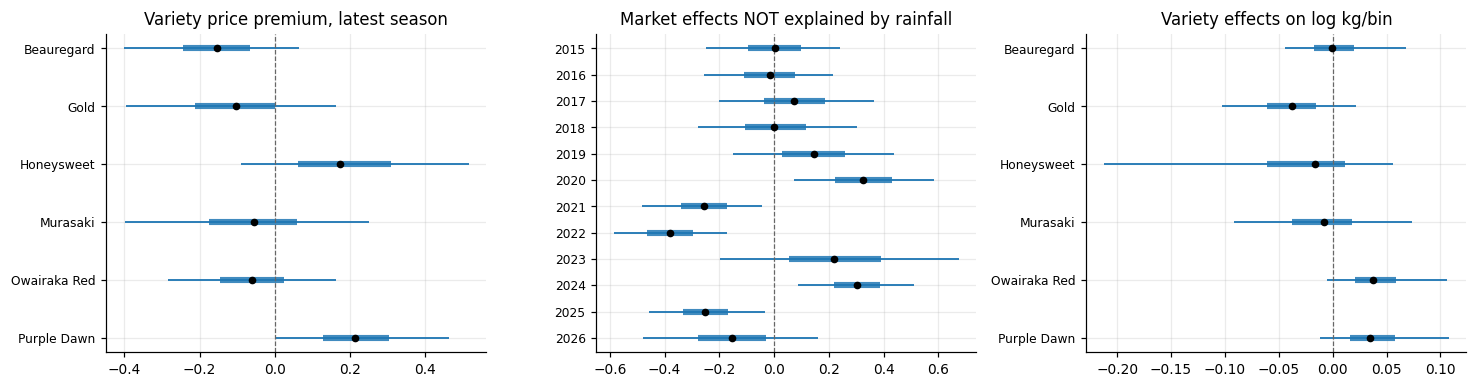

  yield: sigma_variety 0.246 | sigma_season 0.322 | sigma_obs 0.293
 kg/bin: sigma_variety 0.061 | sigma_season 0.055 | sigma_obs 0.078
  price: sigma_variety 0.252 | sigma_season 0.300 | sigma_obs 0.264


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))

forest(axes[0], idata_price, "a_variety", idata_price.attrs["levels_variety"],
       "Variety price premium, latest season" if PRICE_PREMIUM_DRIFT
       else "Variety effects on log price")
forest(axes[1], idata_price, "u_season", idata_price.attrs["levels_season"],
       "Market effects NOT explained by rainfall" if USE_RAINFALL else "Season (market) effects")
forest(axes[2], idata_kgbin, "a_variety", idata_kgbin.attrs["levels_variety"],
       "Variety effects on log kg/bin")

plt.tight_layout(); plt.show()

for nm, idt in [("yield", idata_yield), ("kg/bin", idata_kgbin), ("price", idata_price)]:
    p = az.extract(idt, group="posterior")
    print(f"{nm:>7}: sigma_variety {float(np.asarray(p['sigma_variety']).mean()):.3f} | "
          f"sigma_season {float(np.asarray(p['sigma_season']).mean()):.3f} | "
          f"sigma_obs {float(np.asarray(p['sigma_obs']).mean()):.3f}")

### 7.0 How each variety's price premium has moved

Each line is a variety's premium over the season's market level, on the log scale (0.1 ≈ 10% above
an average variety), with an 80% band; dots mark seasons in which it was priced. `sigma_drift` is
the typical move in one season; if premiums were fixed it would collapse toward zero and the lines
would be flat.

**What it finds.** Premiums do move, by about 7% a season (90% interval 2–14%). Most of the
movement is Beauregard's: level with an average variety at the start of the record, it is now about
15% *below*, as its Premium grade-out fell from 40–50% to under 20% (section 3.3). Purple Dawn has
risen from about +14% to +21%. Owairaka Red and Gold have moved little.

**Two cautions.** The latest premium leans on the most recent deliveries, and the 2026 packout
season is still coming in. And Murasaki, priced once, has no trajectory: its line is one delivery
with drift uncertainty either side.

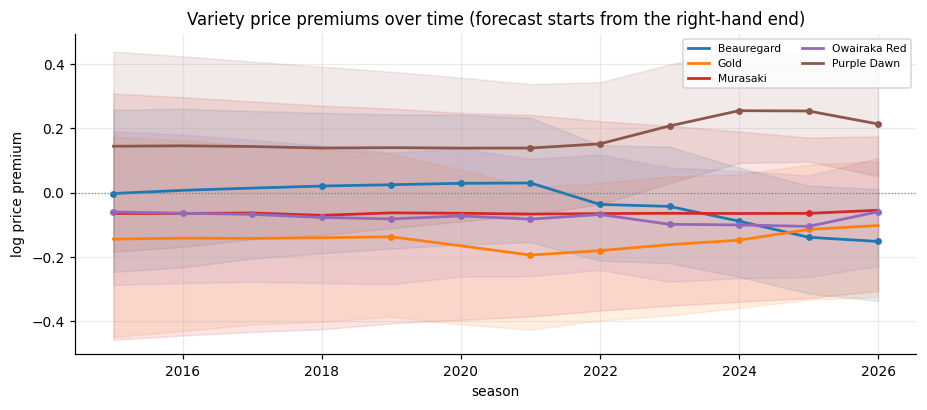

sigma_drift = 0.073 [90% 0.018, 0.137] per season


,"premium, first season","premium, latest season",priced deliveries
Beauregard,-0.00,-0.15,128
Gold,-0.14,-0.10,7
Murasaki,-0.07,-0.05,1
Owairaka Red,-0.06,-0.06,273
Purple Dawn,0.14,0.21,37


In [20]:
if PRICE_PREMIUM_DRIFT:
    pp_ = az.extract(idata_price, group="posterior")
    lvp = list(idata_price.attrs["levels_variety"])
    lsp = idata_price.attrs["levels_season"]
    lvl = np.asarray(pp_["a_variety"])[:, None, :] + np.asarray(pp_["drift_variety"])  # (V, T, S)
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    for i, v in enumerate(lvp):
        if v not in CANDIDATES:
            continue
        lo, md, hi = np.quantile(lvl[i], [0.1, 0.5, 0.9], axis=1)
        ax.plot(lsp, md, lw=1.8, label=v, color=f"C{i}")
        ax.fill_between(lsp, lo, hi, alpha=0.12, color=f"C{i}")
        seen = sorted(price_df.loc[price_df.variety == v, "season"].unique())
        ax.plot(seen, md[[lsp.index(s) for s in seen]], "o", ms=3.5, color=f"C{i}")
    ax.axhline(0, color="0.5", lw=0.8, ls=":")
    ax.set_xlabel("season"); ax.set_ylabel("log price premium")
    ax.set_title("Variety price premiums over time (forecast starts from the right-hand end)")
    ax.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()

    sd_ = np.asarray(pp_["sigma_drift"])
    print(f"sigma_drift = {sd_.mean():.3f} [90% {np.quantile(sd_, .05):.3f}, "
          f"{np.quantile(sd_, .95):.3f}] per season")
    first, last = lsp.index(min(lsp)), len(lsp) - 1
    tab = pd.DataFrame({
        "premium, first season": np.median(lvl[:, first], axis=1),
        "premium, latest season": np.median(lvl[:, last], axis=1),
        "priced deliveries": [int((price_df.variety == v).sum()) for v in lvp],
    }, index=lvp).round(2)
    display(tab.loc[[v for v in lvp if v in CANDIDATES]])

### 7.1 What the models learned about rainfall

Two questions, with different consequences:

**Does rainfall move yield and price?** If so, a drought forecast changes your expected profit and
your risk.

**Do varieties respond to rainfall *differently*?** This decides whether a drought should change
what you plant. If every variety takes a dry or wet year alike, rainfall scales the whole farm up or
down and the best *mix* barely moves. The drought is then something to budget for, not to re-plan
around.

`sigma_rain_variety` answers the second question. It is partially pooled, so without evidence of
differential response it collapses toward zero and every variety gets the common slope.

In [21]:
def rain_curve(idata, mm_grid, variety=None, shape_idx=None):
    "Posterior draws of the rainfall contribution at each season TOTAL."
    # Windowed models need the total apportioned to draw a curve in one dimension. We
    # average over ALL historical shapes, so the curve is "a season of this size, shaped
    # like a typical one" rather than any single year.
    post = az.extract(idata, group="posterior")
    beta = np.moveaxis(np.asarray(post["beta_rain"]), -1, 0)        # (draws, k)
    win = idata.attrs["rain_windows"]
    mm_grid = np.atleast_1d(np.asarray(mm_grid, dtype=float))
    if shape_idx is None:
        Xs = [rain_features(mm_for(win, mm_grid, np.full(len(mm_grid), i)),
                            idata.attrs["rain_form"], win) for i in range(N_SHAPES)]
        X = np.mean(Xs, axis=0)
    else:
        X = rain_features(mm_for(win, mm_grid, np.full(len(mm_grid), shape_idx)),
                          idata.attrs["rain_form"], win)
    out = beta @ X.T                                                # (draws, n)
    if variety is not None and idata.attrs.get("rain_interaction"):
        lv = list(idata.attrs["levels_variety"])
        if variety in lv:
            d = np.moveaxis(np.asarray(post["delta_rain_variety"]), -1, 0)[:, lv.index(variety)]
            out = out + d[:, None] * rain_total_z(mm_grid)[None, :]
    return out


if USE_RAINFALL:
    rain_beta = {}
    for nm, idt in [("yield", idata_yield), ("price", idata_price)]:
        b = np.moveaxis(np.asarray(az.extract(idt, group="posterior")["beta_rain"]), -1, 0)
        rain_beta[nm] = b
        terms = list(idt.attrs["rain_terms"])
        print(f"[{nm:>5}] windows '{idt.attrs['rain_windows']}', "
              f"form '{idt.attrs['rain_form']}'")
        for j, t in enumerate(terms):
            lo, hi = np.quantile(b[:, j], [0.05, 0.95])
            flag = "" if lo < 0 < hi else "   <- credibly non-zero"
            print(f"           {t:>9}: {b[:, j].mean():+.3f}  [90% {lo:+.3f}, {hi:+.3f}]{flag}")

    if RAIN_VARIETY_INTERACTION:
        print()
        for nm, idt in [("yield", idata_yield), ("price", idata_price)]:
            srv = np.asarray(az.extract(idt, group="posterior")["sigma_rain_variety"])
            # compare against the largest common slope in that model
            biggest = np.abs(rain_beta[nm].mean(axis=0)).max()
            print(f"[{nm:>5}] sigma_rain_variety = {srv.mean():.3f} "
                  f"[90% {np.quantile(srv, .05):.3f}, {np.quantile(srv, .95):.3f}]"
                  f"   vs largest common slope {biggest:.3f}")
        print("  -> a variety-specific slope this small next to the common one means the")
        print("     data see little difference between varieties in how they take rain.")

[yield] windows 'three', form 'linear'
               plant: -0.069  [90% -0.261, +0.139]
                grow: -0.308  [90% -0.538, -0.093]   <- credibly non-zero
             harvest: +0.071  [90% -0.128, +0.274]
[price] windows 'split', form 'linear'
               early: -0.053  [90% -0.260, +0.163]
                late: +0.367  [90% +0.156, +0.573]   <- credibly non-zero

[yield] sigma_rain_variety = 0.063 [90% 0.005, 0.165]   vs largest common slope 0.308
[price] sigma_rain_variety = 0.055 [90% 0.003, 0.170]   vs largest common slope 0.367
  -> a variety-specific slope this small next to the common one means the
     data see little difference between varieties in how they take rain.


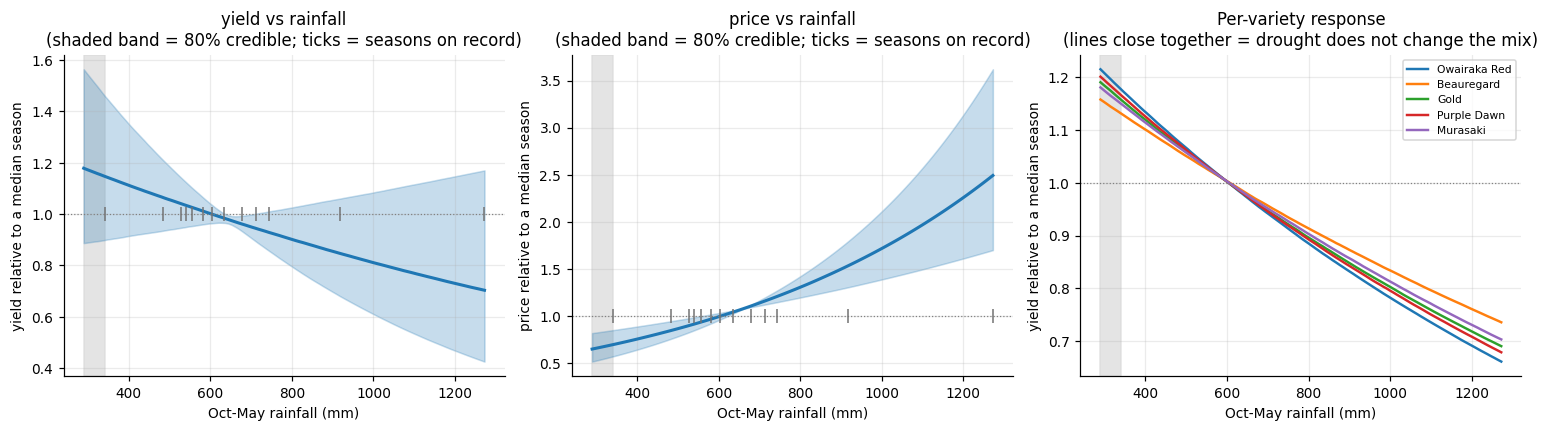

In [22]:
if USE_RAINFALL:
    grid = np.linspace(min(300, rain.min() * 0.85), rain.max(), 120)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))

    # --- farm-wide rainfall response, yield and price
    for ax, (nm, idt) in zip(axes, [("yield", idata_yield), ("price", idata_price)]):
        c = np.exp(rain_curve(idt, grid))
        c = c / np.exp(rain_curve(idt, np.array([rain.median()]))).mean()
        lo, mid, hi = np.quantile(c, [0.1, 0.5, 0.9], axis=0)
        ax.fill_between(grid, lo, hi, alpha=0.25, color="C0")
        ax.plot(grid, mid, color="C0", lw=2)
        ax.axhline(1.0, color="0.5", lw=0.8, ls=":")
        ax.axvspan(grid.min(), rain.min(), color="0.85", alpha=0.7, zorder=0)
        for s, x in rain.items():
            ax.plot([x], [1.0], marker="|", ms=9, color="0.45")
        ax.set_xlabel("Oct-May rainfall (mm)")
        ax.set_ylabel(f"{nm} relative to a median season")
        ax.set_title(f"{nm} vs rainfall\n(shaded band = 80% credible; ticks = seasons on record)")

    # --- per-variety response, the question that decides the mix
    ax = axes[2]
    if RAIN_VARIETY_INTERACTION:
        for v in CANDIDATES:
            if v not in idata_yield.attrs["levels_variety"] or v in NEW_VARIETY_BELIEFS:
                continue
            c = np.exp(rain_curve(idata_yield, grid, variety=v))
            c = c / np.exp(rain_curve(idata_yield, np.array([rain.median()]), variety=v)).mean()
            ax.plot(grid, np.median(c, axis=0), lw=1.6, label=v)
        ax.axhline(1.0, color="0.5", lw=0.8, ls=":")
        ax.axvspan(grid.min(), rain.min(), color="0.85", alpha=0.7, zorder=0)
        ax.legend(fontsize=7)
    ax.set_xlabel("Oct-May rainfall (mm)"); ax.set_ylabel("yield relative to a median season")
    ax.set_title("Per-variety response\n(lines close together = drought does not change the mix)")

    plt.tight_layout(); plt.show()

### 7.2 What comovement is left after rainfall?

A heavy national crop depresses price, so yield and price shocks tend to move against each other
and partly cancel in revenue. Ignoring that would overstate your risk.

For each posterior draw, this correlates the yield and price models' residual season effects
(`u_season`, the part rainfall does **not** explain) across the seasons they share. Rainfall
already carries the shared weather signal, so what is left is weak: about −0.24 on the current
data, with an 80% interval that just reaches zero. It is still probably negative, and it is carried
into the forecast (section 8).

12 seasons shared by both models: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
posterior mean correlation(yield shock, price shock) = -0.24  [80% interval -0.47, +0.01]
P(negative correlation) = 89%


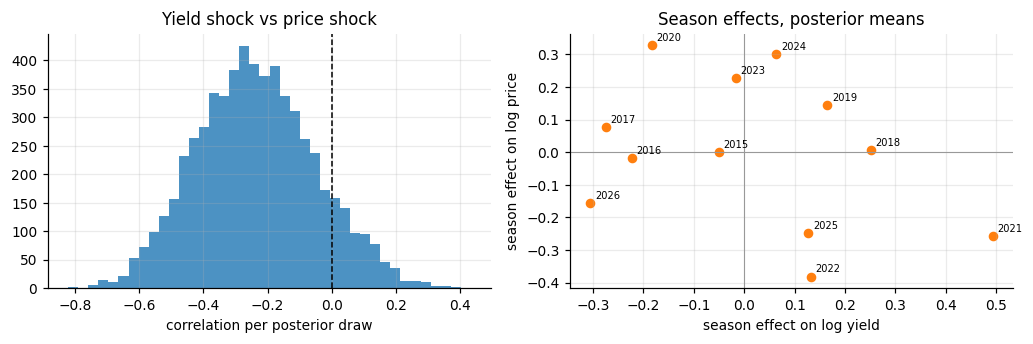

In [23]:
ys = idata_yield.attrs["levels_season"]
ps = idata_price.attrs["levels_season"]
shared = sorted(set(ys) & set(ps))
iy = [ys.index(s) for s in shared]
ip = [ps.index(s) for s in shared]

# u_season is what rainfall does NOT explain, so this is the leftover comovement
_sv = "u_season" if USE_RAINFALL else "b_season"
by = np.moveaxis(np.asarray(az.extract(idata_yield, group="posterior")[_sv]), -1, 0)[:, iy]
bp = np.moveaxis(np.asarray(az.extract(idata_price, group="posterior")[_sv]), -1, 0)[:, ip]

byc = by - by.mean(axis=1, keepdims=True)
bpc = bp - bp.mean(axis=1, keepdims=True)
denom = np.sqrt((byc**2).sum(1) * (bpc**2).sum(1))
RHO_DRAWS = np.where(denom > 0, (byc * bpc).sum(1) / np.where(denom > 0, denom, 1.0), 0.0)

print(f"{len(shared)} seasons shared by both models: {shared}")
print(f"posterior mean correlation(yield shock, price shock) = {RHO_DRAWS.mean():+.2f}  "
      f"[80% interval {np.quantile(RHO_DRAWS, 0.10):+.2f}, {np.quantile(RHO_DRAWS, 0.90):+.2f}]")
print(f"P(negative correlation) = {(RHO_DRAWS < 0).mean():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].hist(RHO_DRAWS, bins=40, color="C0", alpha=0.8)
ax[0].axvline(0, color="k", ls="--", lw=1)
ax[0].set_xlabel("correlation per posterior draw"); ax[0].set_title("Yield shock vs price shock")
ax[1].scatter(by.mean(0), bp.mean(0), s=28, color="C1")
for k, s in enumerate(shared):
    ax[1].annotate(str(s), (by.mean(0)[k], bp.mean(0)[k]), fontsize=6.5,
                   xytext=(3, 3), textcoords="offset points")
ax[1].axhline(0, color="0.6", lw=0.7); ax[1].axvline(0, color="0.6", lw=0.7)
ax[1].set_xlabel("season effect on log yield"); ax[1].set_ylabel("season effect on log price")
ax[1].set_title("Season effects, posterior means")
plt.tight_layout(); plt.show()

COUPLE_YIELD_PRICE = True   # set False to force independent yield and price shocks

## 8. Forecasting an unobserved season

For each posterior draw, the forecast builds one hypothetical next season:

1. **Season shock.** The rainfall scenario's contribution (section 4), plus a fresh residual
   $u_\star \sim \mathcal N(0, \sigma_u)$ for what rainfall does not explain. The yield and price
   residuals are drawn as a correlated pair ($\rho$ from section 7.2), on top of one shared
   rainfall draw.
2. **Shared across varieties.** The residual is common to every variety, so a bad year is bad for
   all of them and the optimiser cannot diversify the weather away. The rainfall part varies by
   variety through the partially pooled slope from section 7.1.
3. **Variety effects.** The posterior $\alpha_v$, plus the variety's effect at `PLAN_SITE`
   ($\gamma_s + \delta_{v,s}$), plus one more season of premium drift. A variety with no records in
   a dataset gets a fresh $\alpha_\star \sim \mathcal N(0,\sigma_\alpha)$: "we do not know, and
   here is how much varieties typically differ". A variety in `NEW_VARIETY_BELIEFS` is simulated as
   the variety it is "like", with its own paddock luck, then scaled by your expectation.
4. **Block noise on yield**, sized for a block of `PLAN_BLOCK_HA` and divided by
   $\sqrt{\texttt{BLOCKS\_PER\_VARIETY}}$, because paddock luck partly averages out over several
   blocks.
5. **Abandonment.** Revenue is scaled by the share of planted area the season lets you lift
   (section 8.1).

Two choices in step 4:

- **Residual noise goes on yield only.** Paddock-to-paddock variation does not average away over a
  handful of paddocks. For kg/bin and $/kg the residual is delivery-to-delivery variation, and you
  are paid the season average over dozens of deliveries, so it very nearly cancels.
- **Normal, not Student-T.** The fitted heavy tail protects the estimates from OCR slips and freak
  paddocks; it is not a forecast that next year contains one. Sampling a $\nu \approx 1.4$ tail
  through $\exp(\cdot)$ produces absurd bin weights.

Everything random comes from `FORECAST_SEED`, so the headline plan (section 11) and the scenario
table (11.3) see the same seasons and agree exactly. Section 11.5 re-runs with other seeds to show
how much the seed matters.

The result is a draws × varieties matrix of margin per hectare that carries parameter uncertainty,
season volatility, paddock noise, and ignorance about untested varieties.

In [24]:
def flat(idata, names):
    "Posterior draws with the sample axis first: scalars (S,), variety params (S, V)."
    post = az.extract(idata, group="posterior")
    return {n: np.moveaxis(np.asarray(post[n]), -1, 0) for n in names}


def component_draws(idata, candidates, season_shock, rng, resid_blocks=None,
                    site=None, override=None):
    "Predictive draws of one component for each candidate variety."
    names = ["mu", "a_variety", "sigma_variety", "sigma_obs"]
    has_site = bool(idata.attrs["levels_site"])
    if has_site:
        names += ["c_site"]
    if idata.attrs.get("variety_site"):
        names += ["d_variety_site", "sigma_variety_site"]
    if idata.attrs.get("area_weighted"):
        names += ["sigma_area"]
    if idata.attrs.get("variety_drift"):
        names += ["sigma_drift"]
    p = flat(idata, names)

    S = p["mu"].shape[0]
    V = len(candidates)
    levels = list(idata.attrs["levels_variety"])

    # variety effects: posterior where we have data, fresh hyperprior draw where we do not
    A = np.empty((S, V))
    borrowed = []
    for j, v in enumerate(candidates):
        if v in levels:
            A[:, j] = p["a_variety"][:, levels.index(v)]
        else:
            A[:, j] = rng.normal(0.0, p["sigma_variety"])
            borrowed.append(v)
        if "sigma_drift" in p:
            # one more season of drift between the latest priced season and the one ahead
            A[:, j] += rng.normal(0.0, p["sigma_drift"])

    sh = np.asarray(season_shock, dtype=float)
    if sh.ndim == 1:                      # one shock shared by every variety
        sh = sh[:, None]
    eta = p["mu"][:, None] + A + sh

    if has_site:
        site_levels = list(idata.attrs["levels_site"])
        g = site_levels.index(site) if site in site_levels else None
        if g is not None:
            eta = eta + p["c_site"][:, g][:, None]
        else:                                    # "average": mean over the farm's sites
            eta = eta + p["c_site"].mean(axis=1)[:, None]
        if idata.attrs.get("variety_site"):      # how THIS variety does at THIS site
            dvs = p["d_variety_site"]            # (S, variety, site)
            for j, v in enumerate(candidates):
                if v in levels:
                    k = levels.index(v)
                    eta[:, j] += dvs[:, k, g] if g is not None else dvs[:, k, :].mean(axis=1)
                else:
                    eta[:, j] += rng.normal(0.0, p["sigma_variety_site"])

    # Idiosyncratic block noise, independent across varieties (the diversifiable part).
    # Normal, not Student-T: the fitted heavy tail guards the estimates against outliers,
    # it is not a claim that next season will contain one. With area weighting, the
    # noise is sized for a block of PLAN_BLOCK_HA.
    if resid_blocks:
        s2 = p["sigma_obs"] ** 2
        if "sigma_area" in p:
            s2 = s2 + p["sigma_area"] ** 2 / PLAN_BLOCK_HA
        eta = eta + rng.standard_normal((S, V)) * (np.sqrt(s2)[:, None] / np.sqrt(resid_blocks))

    out = np.exp(eta)
    if override:
        # The override sets the variety's TYPICAL-season level. The season shock (rainfall
        # plus the residual) still applies, so an overridden variety keeps its year-to-year
        # risk and its response to a drought instead of becoming a riskless fixed price.
        shock = np.broadcast_to(sh, (S, V))
        for j, v in enumerate(candidates):
            if v in override:
                out[:, j] = float(override[v]) * np.exp(shock[:, j])
    return out, borrowed


NAMED_SCENARIOS = {"drought": 0.05, "dry": 0.20, "normal": 0.50, "wet": 0.90}  # rainfall quantiles


def belief_yield_multiplier(b, total_mm, rng):
    "Your yield view as a ratio to the 'like' variety, varying with how wet the season is."
    pts = b["yield_vs_like"]
    xs = np.array([float(rain.quantile(NAMED_SCENARIOS[k])) if isinstance(k, str) else float(k)
                   for k in pts])
    ys = np.log(np.array(list(pts.values()), dtype=float))
    o = np.argsort(xs)
    base = np.interp(np.asarray(total_mm, float), xs[o], ys[o])     # flat beyond the ends
    return np.exp(base + rng.normal(0.0, b.get("yield_sd", 0.0), len(base)))


def belief_price_multiplier(b, n, rng):
    "Your grade-out view as a price ratio: extra Premium points x what a point is worth."
    pts = rng.normal(b.get("premium_pp", 0.0), b.get("premium_pp_sd", 0.0), n)
    return 1.0 + pts / 100.0 * PREMIUM_GAP[b["like"]]


sig_season_y = flat(idata_yield, ["sigma_season"])["sigma_season"]
sig_season_p = flat(idata_price, ["sigma_season"])["sigma_season"]
sig_season_k = flat(idata_kgbin, ["sigma_season"])["sigma_season"]
S = sig_season_y.shape[0]


def scenario_mm(scenario, sd_mm, n, rng):
    "Rainfall for the season being planted: (total mm, borrowed shape, centre mm)."
    # A scenario is a total AND a shape. A forecast total of 430 mm could arrive mostly
    # before Christmas or mostly at harvest, and those are different years. The shape is
    # drawn from the historical record rather than fixed, so scenario-shape uncertainty
    # is carried through like everything else.
    named = NAMED_SCENARIOS
    if isinstance(scenario, str) and scenario == "climatology":
        base = rng.choice(rain.to_numpy(), size=n, replace=True)
        tot = np.clip(base + rng.normal(0, sd_mm, n), 20, None)
        centre = float(rain.median())
    else:
        centre = (float(rain.quantile(named[scenario])) if isinstance(scenario, str)
                  else float(scenario))
        tot = np.clip(rng.normal(centre, sd_mm, n), 20, None)
    # Borrow a whole historical season's SHAPE rather than an average one: the windows
    # do not move together, and averaging them cancels offsetting effects.
    shape = rng.integers(0, N_SHAPES, size=n)
    return tot, shape, centre


def rain_shock(idata, total_mm, shape_idx, candidates, rng):
    "(S,V) rainfall contribution to the season effect, variety-specific where fitted."
    V = len(candidates)
    if not idata.attrs.get("use_rain"):
        return np.zeros((len(total_mm), V))
    post = az.extract(idata, group="posterior")
    beta = np.moveaxis(np.asarray(post["beta_rain"]), -1, 0)      # (S, k)
    win = idata.attrs["rain_windows"]
    X = rain_features(mm_for(win, total_mm, shape_idx),
                      idata.attrs["rain_form"], win)              # (S, k) per-draw scenario
    base = (beta * X).sum(axis=1)                                 # (S,)
    out = np.repeat(base[:, None], V, axis=1)
    if idata.attrs.get("rain_interaction"):
        lv = list(idata.attrs["levels_variety"])
        d_all = np.moveaxis(np.asarray(post["delta_rain_variety"]), -1, 0)
        s_rv = np.asarray(post["sigma_rain_variety"])
        zt = rain_total_z(total_mm)      # interaction is always on the season total
        for j, v in enumerate(candidates):
            d = (d_all[:, lv.index(v)] if v in lv else rng.normal(0.0, s_rv))
            out[:, j] += d * zt
    return out


COST = np.full(len(CANDIDATES), float(COST_PER_HA))   # cost does not vary by variety
rho = RHO_DRAWS if COUPLE_YIELD_PRICE else np.zeros(S)


def simulate(scenario, sd_mm=None, seed=FORECAST_SEED, beliefs=None):
    "One simulated next season per posterior draw, every component, under one scenario."
    # Everything random comes from a generator seeded here, so the same (scenario, seed)
    # always gives the same seasons - which is what lets the headline plan and the
    # scenario table in 11.3 agree.
    rng = np.random.default_rng(seed)
    beliefs = NEW_VARIETY_BELIEFS if beliefs is None else beliefs
    # a variety you have a view on is simulated as the variety it is "like", then scaled
    proxy = [beliefs[v]["like"] if v in beliefs else v for v in CANDIDATES]
    sd = RAIN_SCENARIO_SD_MM if sd_mm is None else sd_mm
    mm, shape, centre = scenario_mm(scenario, sd, S, rng)

    # residual season shocks: the part rainfall does not explain, still correlated
    z1, z2, z3 = rng.standard_normal(S), rng.standard_normal(S), rng.standard_normal(S)
    u_y = sig_season_y * z1
    u_p = sig_season_p * (rho * z1 + np.sqrt(np.clip(1 - rho**2, 0, 1)) * z2)
    sh_y = rain_shock(idata_yield, mm, shape, proxy, rng) + u_y[:, None]
    sh_p = rain_shock(idata_price, mm, shape, proxy, rng) + u_p[:, None]
    sh_k = sig_season_k * z3                  # no rainfall term in the kg/bin model

    # paddock-level residual applies to yield; delivery-level residual averages out
    Y, b_y = component_draws(idata_yield, proxy, sh_y, rng,
                             resid_blocks=BLOCKS_PER_VARIETY, site=PLAN_SITE)
    K, b_k = component_draws(idata_kgbin, proxy, sh_k, rng, override=KGBIN_OVERRIDE)
    P, b_p = component_draws(idata_price, proxy, sh_p, rng, override=PRICE_OVERRIDE)
    for j, v in enumerate(CANDIDATES):
        if v in beliefs:
            Y[:, j] = Y[:, j] * belief_yield_multiplier(beliefs[v], mm, rng)
            P[:, j] = P[:, j] * belief_price_multiplier(beliefs[v], S, rng)

    # Yield is per hectare LIFTED. The share of area a wet season lets you lift is the
    # one and only place abandonment enters (section 8.1).
    loss = harvest_loss_fraction(mm, shape)
    revenue = Y * K * P * (1.0 - loss)[:, None]           # $/ha planted
    return dict(scenario=scenario, mm=mm, shape=shape, centre=centre,
                Y=Y, K=K, P=P, loss=loss, revenue=revenue, margin=revenue - COST,
                borrowed={"yield": b_y, "kg/bin": b_k, "price": b_p})

### 8.1 Pricing the paddocks a wet season takes off you

Yield is per hectare *lifted*, so lost paddocks enter here and only here, as a share of planted
area:

$$\text{loss} = \min\!\left(\text{max\_loss},\; \frac{\max(0,\ \text{rain} - \text{threshold})}{100} \times \text{slope}_{\text{site}}\right)$$

Revenue per hectare planted is multiplied by $(1-\text{loss})$.

**The slope is fitted.** With `loss_per_100mm = "fit"`, each site's slope is a least-squares fit to
its recorded completion (section 2). The record holds one season with abandonment (2023, 1272 mm)
and one wet near-miss (2026, 918 mm, nothing lost). At Hodgson that gives about 15% of planted area
lost per 100 mm above 900 mm, or 57% in a 2023-sized season; Te Kowhai comes out at about 1.4%.
The forecast uses the curve for `PLAN_SITE`.

**The threshold is not fitted.** 2026 (918 mm) lost nothing and 2023 (1272 mm) lost a lot, so the
data only place the cliff somewhere between them. 900 mm sits just below 2026, a slightly cautious
choice for a season that was plainly close. **If your experience puts the cliff elsewhere, move
`threshold_mm`.** It changes the wet-tail risk more than any other single number here, and does not
touch the drought answer, which never reaches it.

Two assumptions:

- **Every variety loses the same share of area.** One season cannot say whether some varieties rot
  or strand more readily.
- **One curve per site.** "Hodgson" means the Hodgson paddocks planted in 2023; if some drain better
  than others, the curve averages over them.

abandonment driver 'total', threshold 900 mm
  Hodgson  : 15.2% of planted area lost per 100 mm above it
  Te Kowhai:  1.4% of planted area lost per 100 mm above it
  farm     : 10.6% of planted area lost per 100 mm above it
-> the forecast uses 15.2% per 100 mm (fitted to Hodgson's own record)


,rain mm,Hodgson lost,Hodgson fitted,Te Kowhai lost,Te Kowhai fitted,farm lost,farm fitted
season,,,,,,,
2023,1272.0,57%,57%,5%,5%,40%,39%
2026,918.0,0%,3%,-,0%,0%,2%


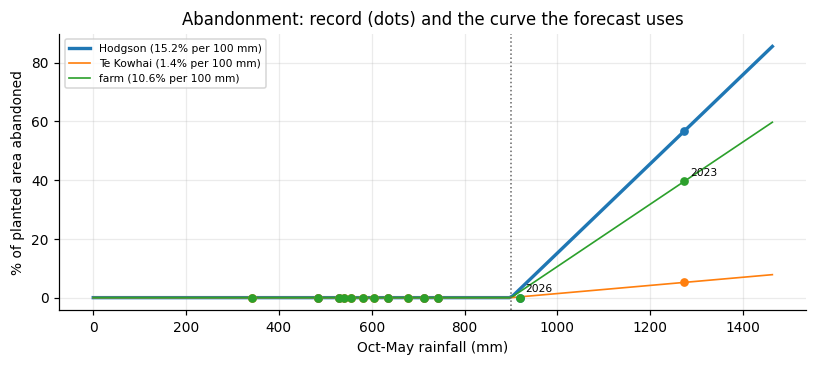

In [25]:
HL = HARVEST_LOSS


def loss_driver(total_mm, shape_idx):
    "The rainfall figure abandonment responds to: the season total, or one window of it."
    total_mm = np.asarray(total_mm, dtype=float)
    if HL["driver"] == "total" or not HAVE_MONTHLY:
        return total_mm
    col = RAIN_SHARES["three"].columns.get_loc(HL["driver"])
    return total_mm * RAIN_SHARES["three"].to_numpy()[np.asarray(shape_idx, dtype=int), col]


# the record: each season's own driver, and the share of planted area it cost
HIST_DRIVER = pd.Series(loss_driver(rain_df.total.to_numpy(), np.arange(N_SHAPES)),
                        index=rain_df.index)
hist_x = np.maximum(0.0, HIST_DRIVER - HL["threshold_mm"]) / 100.0
_sites = COMPLETION_SITE.index.get_level_values("site_short")
LOSS_OBS = {site: 1.0 - COMPLETION_SITE.xs(site, level="site_short")
            for site in ["Hodgson", "Te Kowhai"] if site in _sites}
LOSS_OBS["farm"] = 1.0 - COMPLETION_FARM


def fit_slope(obs):
    "Least-squares slope through the origin: share of area lost per 100 mm over threshold."
    s = obs.index.intersection(hist_x.index)
    x, y = hist_x.loc[s].to_numpy(), obs.loc[s].to_numpy()
    return float((x * y).sum() / (x * x).sum()) if (x * x).sum() > 0 else 0.0


LOSS_SLOPE = {site: fit_slope(o) for site, o in LOSS_OBS.items()}
PLAN_KEY = site_short(PLAN_SITE) if PLAN_SITE != "average" else "farm"
if HL["loss_per_100mm"] == "fit":
    PLAN_LOSS_SLOPE = LOSS_SLOPE.get(PLAN_KEY, LOSS_SLOPE["farm"])
    _basis = f"fitted to {PLAN_KEY}'s own record" if PLAN_KEY in LOSS_SLOPE else "fitted farm-wide"
else:
    PLAN_LOSS_SLOPE = float(HL["loss_per_100mm"])
    _basis = "set by hand in HARVEST_LOSS"


def harvest_loss_fraction(total_mm, shape_idx, slope=None):
    "Fraction of PLANTED area expected to be abandoned, given how wet the season is."
    slope = PLAN_LOSS_SLOPE if slope is None else slope
    over = np.maximum(0.0, loss_driver(total_mm, shape_idx) - HL["threshold_mm"]) / 100.0
    return np.clip(over * slope, 0.0, HL["max_loss"])


print(f"abandonment driver '{HL['driver']}', threshold {HL['threshold_mm']:.0f} mm")
for site, b in LOSS_SLOPE.items():
    print(f"  {site:<9}: {100*b:4.1f}% of planted area lost per 100 mm above it")
print(f"-> the forecast uses {100*PLAN_LOSS_SLOPE:.1f}% per 100 mm ({_basis})")

# observed against fitted, for every season at or above the threshold or with any loss
wet = [s for s in HIST_DRIVER.index
       if hist_x[s] > 0 or LOSS_OBS["farm"].get(s, 0.0) > 0]
tbl = pd.DataFrame({"rain mm": HIST_DRIVER.loc[wet].round(0)})
for site, o in LOSS_OBS.items():
    tbl[f"{site} lost"] = [f"{o[s]:.0%}" if s in o.index else "-" for s in wet]
    tbl[f"{site} fitted"] = [f"{min(HL['max_loss'], hist_x[s] * LOSS_SLOPE[site]):.0%}"
                             for s in wet]
display(tbl)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
gmm = np.linspace(0, HIST_DRIVER.max() * 1.15, 200)
for i, (site, b) in enumerate(LOSS_SLOPE.items()):
    curve = np.clip(np.maximum(0, gmm - HL["threshold_mm"]) / 100 * b, 0, HL["max_loss"])
    ax.plot(gmm, 100 * curve, color=f"C{i}", lw=2.2 if site == PLAN_KEY else 1.1,
            label=f"{site} ({100*b:.1f}% per 100 mm)")
    o = LOSS_OBS[site]
    s = o.index.intersection(HIST_DRIVER.index)
    ax.scatter(HIST_DRIVER.loc[s], 100 * o.loc[s], color=f"C{i}", s=22, zorder=5)
for s in wet:
    ax.annotate(str(s), (HIST_DRIVER[s], 100 * LOSS_OBS["farm"].get(s, 0.0)), fontsize=7,
                xytext=(4, 4), textcoords="offset points")
ax.axvline(HL["threshold_mm"], color="0.4", ls=":", lw=1)
ax.set_xlabel(("Oct-May" if HL["driver"] == "total" else HL["driver"]) + " rainfall (mm)")
ax.set_ylabel("% of planted area abandoned")
ax.set_title("Abandonment: record (dots) and the curve the forecast uses")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

### 8.2 Next season's margin per hectare

The simulation under the rainfall scenario set in section 1. For every posterior draw: yield at
your planting site, bin weight and price for each variety, and revenue scaled by the share of
planted area lifted.

In [26]:
SIM = simulate(RAIN_SCENARIO)
RAIN_DRAWS, RAIN_SHAPE, RAIN_CENTRE = SIM["mm"], SIM["shape"], SIM["centre"]
Y, K, P, LOSS = SIM["Y"], SIM["K"], SIM["P"], SIM["loss"]
REVENUE, MARGIN = SIM["revenue"], SIM["margin"]

print(f"{S:,} posterior draws -> {S:,} simulated {PLANTING_SEASON} seasons "
      f"at {PLAN_SITE} (seed {FORECAST_SEED})")
print(f"rainfall scenario: '{RAIN_SCENARIO}' -> centre {RAIN_CENTRE:.0f} mm, "
      f"sd {RAIN_SCENARIO_SD_MM:.0f} mm")
print(f"  drawn range (80%): {np.quantile(RAIN_DRAWS, .1):.0f} - "
      f"{np.quantile(RAIN_DRAWS, .9):.0f} mm   vs history {rain.min():.0f} - {rain.max():.0f} mm")
if HAVE_MONTHLY:
    print("  season shapes borrowed from history; implied window rainfall (80% range):")
    for win in RAIN_COLS[RAIN_WINDOWS["yield"]]:
        col = RAIN_SHARES[RAIN_WINDOWS["yield"]].columns.get_loc(win)
        wmm = RAIN_DRAWS * RAIN_SHARES[RAIN_WINDOWS["yield"]].to_numpy()[RAIN_SHAPE, col]
        print(f"    {win:<8} {np.quantile(wmm, .1):5.0f} - {np.quantile(wmm, .9):5.0f} mm")
below = float((RAIN_DRAWS < rain.min()).mean())
if below > 0.05:
    print(f"  WARNING: {below:.0%} of scenario draws are drier than ANY season on record "
          f"({rain.min():.0f} mm, {rain.idxmin()}).")
    print("  The model is extrapolating there and cannot know how the crop behaves. "
          "Treat as indicative.")
print(f"residual yield/price coupling: {'ON' if COUPLE_YIELD_PRICE else 'OFF'} "
      f"(mean rho {rho.mean():+.2f})")
print(f"area lost to abandonment: expected {LOSS.mean():.1%}, P(any loss) "
      f"{(LOSS > 0).mean():.0%}, worst 10% of draws lose {np.quantile(LOSS, 0.9):.0%}")

for nm, b in SIM["borrowed"].items():
    if b:
        print(f"  {nm}: no own data for {b} - drawn from the variety population distribution")

comp = pd.DataFrame({
    "bins/ha":    Y.mean(0).round(1),
    "kg/bin":     K.mean(0).round(0),
    "$/kg":       P.mean(0).round(2),
    "t/ha":       ((Y * K).mean(0) / 1000).round(1),
    "revenue/ha": REVENUE.mean(0).round(0),
    "cost/ha":    COST.round(0),
    "margin/ha":  MARGIN.mean(0).round(0),
    "margin p10": np.quantile(MARGIN, 0.10, axis=0).round(0),
    "margin p90": np.quantile(MARGIN, 0.90, axis=0).round(0),
    "P(loss)":    (MARGIN < 0).mean(0).round(2),
}, index=CANDIDATES)
comp["P(best/ha)"] = np.round(
    np.bincount(MARGIN.argmax(axis=1), minlength=len(CANDIDATES)) / S, 2)
display(comp.sort_values("margin/ha", ascending=False))

6,000 posterior draws -> 6,000 simulated 2027 seasons at Hodgson (91 Hodgson Road) (seed 7)
rainfall scenario: 'drought' -> centre 427 mm, sd 90 mm
  drawn range (80%): 311 - 540 mm   vs history 341 - 1272 mm
  season shapes borrowed from history; implied window rainfall (80% range):
    plant      101 -   244 mm
    grow        42 -   154 mm
    harvest    108 -   230 mm
  The model is extrapolating there and cannot know how the crop behaves. Treat as indicative.
residual yield/price coupling: ON (mean rho -0.24)
area lost to abandonment: expected 0.0%, P(any loss) 0%, worst 10% of draws lose 0%


,bins/ha,kg/bin,$/kg,t/ha,revenue/ha,cost/ha,margin/ha,margin p10,margin p90,P(loss),P(best/ha)
Purple Dawn,42.7,654.0,1.71,27.9,46491.0,12000.0,34491.0,5702.0,72531.0,0.03,0.68
Bellevue,40.4,631.0,1.28,25.5,31778.0,12000.0,19778.0,101.0,45001.0,0.10,0.12
Murasaki,35.6,624.0,1.32,22.2,28577.0,12000.0,16577.0,-2491.0,42384.0,0.17,0.09
Beauregard,37.9,631.0,1.18,23.9,27666.0,12000.0,15666.0,-1356.0,37172.0,0.13,0.05
Gold,37.0,605.0,1.22,22.4,26590.0,12000.0,14590.0,-1998.0,36355.0,0.16,0.05
Owairaka Red,26.2,656.0,1.31,17.2,22076.0,12000.0,10076.0,-3407.0,27166.0,0.23,0.01


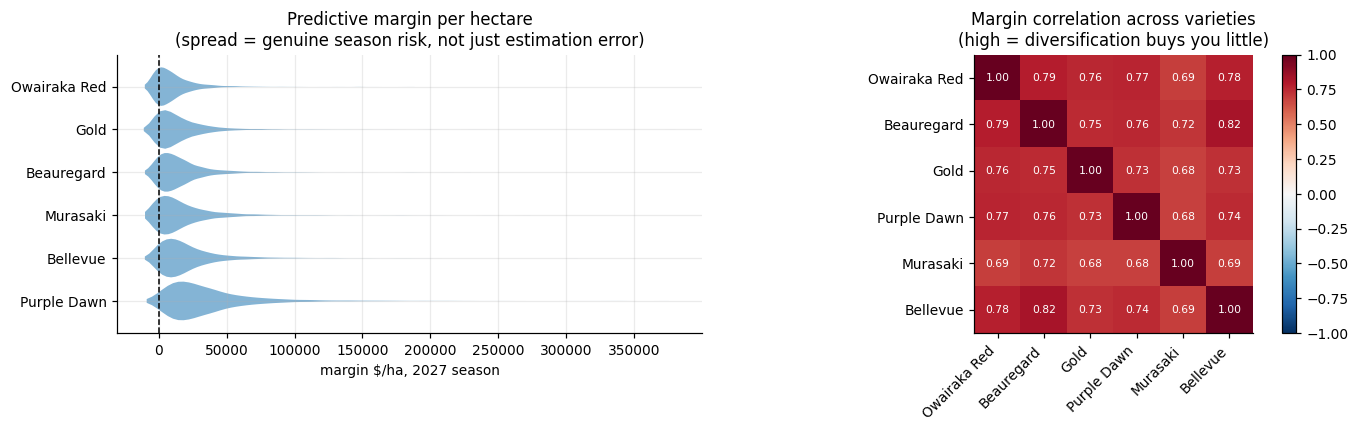

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))

order = np.argsort(-MARGIN.mean(0))
parts = axes[0].violinplot([MARGIN[:, j] for j in order], vert=False, showextrema=False,
                           widths=0.9)
for pc in parts["bodies"]:
    pc.set_alpha(0.55)
axes[0].set_yticks(range(1, len(order) + 1))
axes[0].set_yticklabels([CANDIDATES[j] for j in order])
axes[0].axvline(0, color="k", ls="--", lw=1)
axes[0].set_xlabel(f"margin $/ha, {PLANTING_SEASON} season")
axes[0].set_title("Predictive margin per hectare\n(spread = genuine season risk, not just estimation error)")

cor = np.corrcoef(MARGIN.T)
im = axes[1].imshow(cor, vmin=-1, vmax=1, cmap="RdBu_r")
axes[1].set_xticks(range(len(CANDIDATES))); axes[1].set_yticks(range(len(CANDIDATES)))
axes[1].set_xticklabels(CANDIDATES, rotation=45, ha="right"); axes[1].set_yticklabels(CANDIDATES)
for a in range(len(CANDIDATES)):
    for b in range(len(CANDIDATES)):
        axes[1].text(b, a, f"{cor[a, b]:.2f}", ha="center", va="center", fontsize=7,
                     color="white" if abs(cor[a, b]) > 0.6 else "black")
axes[1].set_title("Margin correlation across varieties\n(high = diversification buys you little)")
axes[1].grid(False)
plt.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout(); plt.show()

## 9. Turning margins into an allocation

With a draws × varieties matrix $M$ of margin per hectare, total profit for an allocation $w$
(hectares per variety) is $\Pi_s = \sum_v M_{sv} w_v$, one figure per simulated season. The
optimiser chooses $w$ to maximise a risk-adjusted summary of that distribution:

| `RISK_MEASURE` | objective | behaviour |
|---|---|---|
| `"mean"` | $\mathbb E[\Pi]$ | risk-neutral; piles into the best variety up to its ceiling |
| `"meanvar"` | $\mathbb E[\Pi] - \lambda\,\mathrm{sd}(\Pi)$ | penalises spread in both directions |
| `"cvar"` | $\mathbb E[\Pi] - \lambda\,(\mathbb E[\Pi] - \mathrm{CVaR}_\alpha)$ | penalises only the bad tail: the average of the worst $\alpha$ of seasons |

`"cvar"` usually suits a grower best: what matters is how bad a bad year gets, not symmetric
variance. It is solved by multi-start SLSQP within the area limits, checked against a random
search.

In [28]:
def summarise(profit, alpha=CVAR_ALPHA):
    var = np.quantile(profit, alpha)
    tail = profit[profit <= var]
    return dict(mean=profit.mean(), sd=profit.std(),
                p10=np.quantile(profit, 0.10), p90=np.quantile(profit, 0.90),
                cvar=tail.mean() if tail.size else var, p_loss=(profit < 0).mean())


def objective(w, M, measure, lam, alpha):
    p = M @ w
    if measure == "mean":
        return -p.mean()
    if measure == "meanvar":
        return -(p.mean() - lam * p.std())
    if measure == "cvar":
        var = np.quantile(p, alpha)
        tail = p[p <= var]
        cvar = tail.mean() if tail.size else var
        return -(p.mean() - lam * (p.mean() - cvar))
    raise ValueError(measure)


def repair(w, lo, hi, total, iters=60):
    "Project onto {lo <= w <= hi, sum(w) == total} by redistributing the surplus."
    w = np.clip(w, lo, hi)
    for _ in range(iters):
        gap = total - w.sum()
        if abs(gap) < 1e-9:
            break
        room = (hi - w) if gap > 0 else (w - lo)
        if room.sum() <= 1e-12:
            break
        w = np.clip(w + gap * room / room.sum(), lo, hi)
    return w


def optimise(M, candidates, total, lo, hi, measure, lam, alpha=CVAR_ALPHA,
             n_starts=24, n_random=4000, rng=RNG, verbose=False):
    V = len(candidates)
    lo = np.array([lo.get(v, 0.0) for v in candidates], float)
    hi = np.minimum(np.array([hi.get(v, total) for v in candidates], float), total)
    if lo.sum() > total + 1e-9:
        raise ValueError(f"MIN_AREA_HA sums to {lo.sum():.1f} ha > TOTAL_AREA_HA {total:.1f}")
    if hi.sum() < total - 1e-9:
        raise ValueError(f"MAX_AREA_HA sums to {hi.sum():.1f} ha < TOTAL_AREA_HA {total:.1f}; "
                         "raise a ceiling or lower the total area")

    f = lambda w: objective(w, M, measure, lam, alpha)
    cons = [{"type": "eq", "fun": lambda w: w.sum() - total}]
    bounds = list(zip(lo, hi))
    free = total - lo.sum()

    # Random search over the feasible set: robust, and the benchmark SLSQP must beat.
    pool = [repair(lo + free * d, lo, hi, total)
            for d in rng.dirichlet(np.ones(V), size=n_random)]
    vals = np.array([f(w) for w in pool])
    best_rand = pool[int(vals.argmin())]

    # SLSQP polish from several starts. The CVaR objective is non-smooth, so SLSQP
    # often reports failure; we judge every iterate on its own objective value rather
    # than trusting r.success, and keep the start itself as a fallback.
    cands = [(vals.min(), best_rand)]
    starts = [repair(lo + free * np.ones(V) / V, lo, hi, total), best_rand]
    starts += [pool[i] for i in np.argsort(vals)[:max(0, n_starts - 2)]]
    for w0 in starts:
        try:
            r = optimize.minimize(f, w0, method="SLSQP", bounds=bounds,
                                  constraints=cons, options={"maxiter": 300, "ftol": 1e-9})
        except Exception:
            continue
        w = repair(np.asarray(r.x, float), lo, hi, total)
        cands.append((f(w), w))

    best_val, best = min(cands, key=lambda t: t[0])
    if verbose:
        gain = (vals.min() - best_val) / max(abs(vals.min()), 1e-9)
        print(f"  SLSQP improved on {len(pool)}-point random search by {100*gain:.2f}%")
    return repair(best, lo, hi, total)


# thin the draws a little to keep the many optimiser evaluations quick
THIN = max(1, S // 4000)


def plan(M, measure=None, lam=None, seed=FORECAST_SEED, n_starts=10, max_area=None, **kw):
    "The optimiser with the settings every section shares: same inputs, same plan."
    return optimise(M[::THIN], CANDIDATES, TOTAL_AREA_HA, MIN_AREA_HA,
                    MAX_AREA_HA if max_area is None else max_area,
                    RISK_MEASURE if measure is None else measure,
                    RISK_AVERSION if lam is None else lam,
                    n_starts=n_starts, rng=np.random.default_rng(seed), **kw)


print(f"optimising over {len(MARGIN[::THIN]):,} simulated seasons "
      f"(thinned from {S:,} by {THIN}x)")

optimising over 6,000 simulated seasons (thinned from 6,000 by 1x)


In [29]:
W = {}
W["risk-neutral"] = plan(MARGIN, "mean", 0.0)
W[f"recommended ({RISK_MEASURE}, lambda={RISK_AVERSION})"] = plan(MARGIN)

# equal split within the constraints, as a naive benchmark
_lo = np.array([MIN_AREA_HA.get(v, 0.0) for v in CANDIDATES])
W["equal split"] = _lo + (TOTAL_AREA_HA - _lo.sum()) * np.ones(len(CANDIDATES)) / len(CANDIDATES)

# what you actually planted in the most recent season, rescaled to this year's area
last = yield_df.season.max()
act = (yield_df[yield_df.season == last].groupby("variety").area_ha.sum()
       .reindex(CANDIDATES).fillna(0.0))
if act.sum() > 0:
    W[f"{last} mix (rescaled)"] = (act / act.sum() * TOTAL_AREA_HA).to_numpy()

rows = []
for name, w in W.items():
    st = summarise(MARGIN @ w)
    rows.append({"allocation": name, **{f"{v} ha": round(x, 1) for v, x in zip(CANDIDATES, w)},
                 "E[profit]": round(st["mean"]), "sd": round(st["sd"]),
                 "p10": round(st["p10"]), "p90": round(st["p90"]),
                 f"CVaR{int(CVAR_ALPHA*100)}": round(st["cvar"]),
                 "P(loss)": round(st["p_loss"], 2)})
compare = pd.DataFrame(rows).set_index("allocation")
display(compare)

,Owairaka Red ha,Beauregard ha,Gold ha,Purple Dawn ha,Murasaki ha,Bellevue ha,E[profit],sd,p10,p90,CVaR20,P(loss)
allocation,,,,,,,,,,,,
risk-neutral,1.0,4.0,0.0,5.0,3.0,2.0,334483,320507,37098,719254,24807,0.06
"recommended (cvar, lambda=1.0)",1.0,4.0,0.5,5.0,2.5,2.0,333527,319458,35823,716247,25049,0.06
equal split,3.3,2.3,2.3,2.3,2.3,2.3,269494,276773,11709,593968,2567,0.08
2026 mix (rescaled),5.6,4.6,0.0,3.8,1.0,0.1,276269,284195,12286,611191,3402,0.08


## 10. The efficient frontier

Sweeping $\lambda$ upward from 0 (pure expected profit) traces the allocations that are not
dominated: each is the most profitable mix at its level of downside risk. The gap between the
frontier and the benchmark points (equal split, last season's mix) is what the optimisation adds.

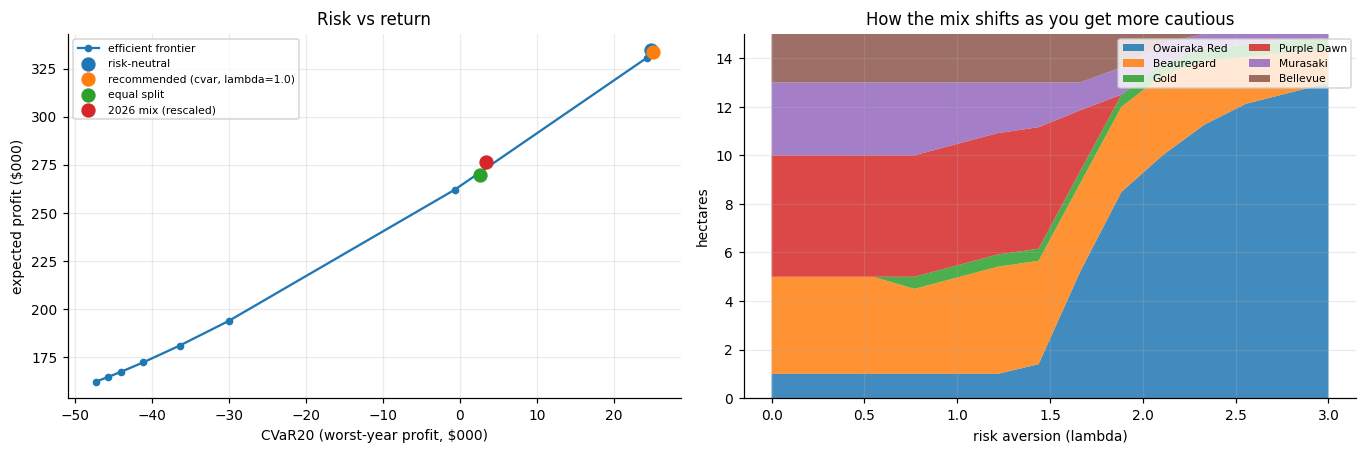

In [30]:
lams = np.concatenate([[0.0], np.linspace(0.1, 3.0, 14)])
frontier = []
for lam in lams:
    w = plan(MARGIN, lam=lam)
    st = summarise(MARGIN @ w)
    frontier.append({"lambda": lam, "w": w, **st})
fr = pd.DataFrame(frontier)

xkey = "cvar" if RISK_MEASURE == "cvar" else "sd"
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

axes[0].plot(fr[xkey] / 1000, fr["mean"] / 1000, "-o", ms=4, color="C0", label="efficient frontier")
for name, w in W.items():
    st = summarise(MARGIN @ w)
    axes[0].scatter(st[xkey] / 1000, st["mean"] / 1000, s=70, zorder=5, label=name)
axes[0].set_xlabel(f"{'CVaR' + str(int(CVAR_ALPHA*100)) + ' (worst-year profit, $000)' if xkey=='cvar' else 'sd of profit ($000)'}")
axes[0].set_ylabel("expected profit ($000)")
axes[0].set_title("Risk vs return"); axes[0].legend(fontsize=7)

Wfr = np.vstack(fr["w"].to_numpy())
axes[1].stackplot(fr["lambda"], Wfr.T, labels=CANDIDATES, alpha=0.85)
axes[1].set_xlabel("risk aversion (lambda)"); axes[1].set_ylabel("hectares")
axes[1].set_title("How the mix shifts as you get more cautious")
axes[1].legend(fontsize=7, loc="upper right", ncol=2)
axes[1].set_ylim(0, TOTAL_AREA_HA)

plt.tight_layout(); plt.show()

## 11. The recommendation

Read the plan together with the limits in section 1. On the current data four of the six varieties
sit on a limit: Purple Dawn, Bellevue and Gold at their ceilings, and Owairaka Red at its floor.
Beauregard and Murasaki share the remaining 6.5 ha, and that split is where the model is genuinely
choosing.

- The model would plant **more Purple Dawn and Bellevue** if you let it, so those two ceilings are
  the numbers most worth getting right.
- It would plant **less Owairaka Red**, so the floor is costing you money. That is fine if it keeps
  a seed line or a contract alive, but worth knowing.
- **Gold** takes its 0.5 ha as a hedge. The risk-neutral plan (section 9) plants none.

Beauregard is held back by its price drift (section 7.0): the forecast starts from its recent,
weaker premium rather than its 12-year average, and that is also what lets Murasaki in. Section 11.5
shows how firm each figure is.

PLANTING PLAN - 2027 season, 15 ha, objective = cvar (lambda=1.0)


,hectares,share,E[margin/ha],E[contribution],price evidence
Purple Dawn,5.0,0.333,34491.0,172456.0,own data
Beauregard,4.0,0.264,15666.0,62038.0,own data
Murasaki,2.5,0.169,16577.0,42105.0,thin - heavily shrunk
Bellevue,2.0,0.133,19778.0,39557.0,your view vs Beauregard
Owairaka Red,1.0,0.067,10076.0,10076.0,own data
Gold,0.5,0.033,14590.0,7295.0,own data


Expected profit      $     333,527
80% interval         $      35,823  to  $716,247
Worst 20% of seasons  $      25,049   (CVaR)
P(loss)                         6%

vs your 2026 mix on the same 15 ha: expected profit +57,257 (+20.7%), worst-case +21,647


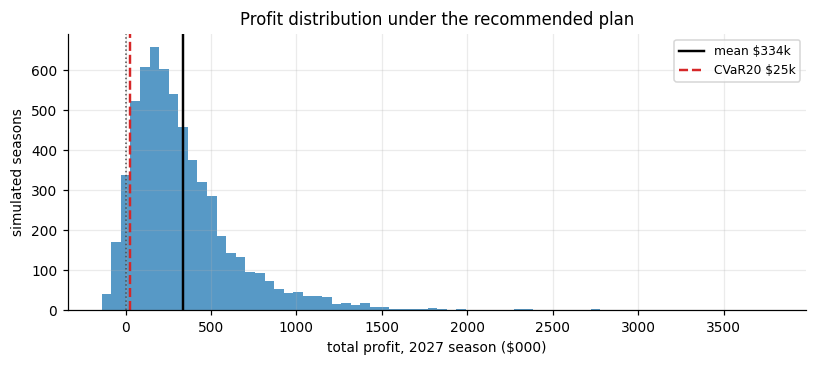


saved to C:\Users\wjsim\Documents\Kumara Variety Modelling\outputs


In [31]:
rec_key = f"recommended ({RISK_MEASURE}, lambda={RISK_AVERSION})"
w_rec = W[rec_key]
profit = MARGIN @ w_rec
st = summarise(profit)

rec = pd.DataFrame({
    "hectares": np.round(w_rec, 1),
    "share": np.round(w_rec / TOTAL_AREA_HA, 3),
    "E[margin/ha]": MARGIN.mean(0).round(0),
    "E[contribution]": (MARGIN.mean(0) * w_rec).round(0),
    "price evidence": [PRICE_EVIDENCE.get(v, "pooled mean only") for v in CANDIDATES],
}, index=CANDIDATES).sort_values("hectares", ascending=False)
rec = rec[rec.hectares > 0.05]

print(f"PLANTING PLAN - {PLANTING_SEASON} season, {TOTAL_AREA_HA:.0f} ha, "
      f"objective = {RISK_MEASURE} (lambda={RISK_AVERSION})")
print("=" * 78)
display(rec)
print(f"Expected profit      ${st['mean']:>12,.0f}")
print(f"80% interval         ${st['p10']:>12,.0f}  to  ${st['p90']:,.0f}")
print(f"Worst {int(CVAR_ALPHA*100)}% of seasons  ${st['cvar']:>12,.0f}   (CVaR)")
print(f"P(loss)              {st['p_loss']:>13.0%}")

if f"{last} mix (rescaled)" in W:
    base = summarise(MARGIN @ W[f"{last} mix (rescaled)"])
    print(f"\nvs your {last} mix on the same {TOTAL_AREA_HA:.0f} ha: "
          f"expected profit {st['mean'] - base['mean']:+,.0f} "
          f"({(st['mean']/base['mean'] - 1):+.1%}), "
          f"worst-case {st['cvar'] - base['cvar']:+,.0f}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(profit / 1000, bins=70, color="C0", alpha=0.75)
ax.axvline(st["mean"] / 1000, color="k", lw=1.6, label=f"mean ${st['mean']/1000:,.0f}k")
ax.axvline(st["cvar"] / 1000, color="C3", lw=1.6, ls="--",
           label=f"CVaR{int(CVAR_ALPHA*100)} ${st['cvar']/1000:,.0f}k")
ax.axvline(0, color="0.3", lw=1, ls=":")
ax.set_xlabel(f"total profit, {PLANTING_SEASON} season ($000)"); ax.set_ylabel("simulated seasons")
ax.set_title("Profit distribution under the recommended plan"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

rec.to_csv(OUT_DIR / f"planting_plan_{PLANTING_SEASON}.csv")
compare.to_csv(OUT_DIR / f"allocation_comparison_{PLANTING_SEASON}.csv")
comp.to_csv(OUT_DIR / f"variety_margins_{PLANTING_SEASON}.csv")
print(f"\nsaved to {OUT_DIR}")

### 11.1 Your cost assumption cannot change the plan

Cost varies by paddock but not by variety, so with the total area $A=\sum_v w_v$ fixed:

$$\Pi \;=\; \sum_v w_v (R_v - C) \;=\; \underbrace{\sum_v w_v R_v}_{\text{depends on the mix}} \;-\; \underbrace{C \cdot A}_{\text{constant}}$$

The cost term does not depend on $w$. It shifts the mean, the CVaR and every quantile by the same
amount and leaves the spread alone, so all three objectives rank allocations identically whatever
$C$ is. The optimal mix is *exactly* invariant, and the cell below demonstrates it. Cost changes
the profit you book and your probability of a loss, not which varieties to plant.

This rests on two conditions:

- **You plant the whole area.** If leaving ground fallow is a real option, cost decides whether the
  marginal hectare is worth planting (see the break-even table in 11.2).
- **Cost is unrelated to variety.** If the specialty lines always land on dearer or more distant
  paddocks, that is a variety-linked cost, and the invariance weakens to that extent.

In [32]:
rows = []
for m in [0.6, 0.8, 1.0, 1.25, 1.5]:
    Mm = REVENUE - COST * m
    w = plan(Mm)
    pl = Mm @ w
    rows.append({"cost $/ha": round(COST_PER_HA * m),
                 **{v: round(x, 1) for v, x in zip(CANDIDATES, w)},
                 "E[profit]": round(pl.mean()),
                 f"CVaR{int(CVAR_ALPHA*100)}": round(summarise(pl)["cvar"]),
                 "P(loss)": round(float((pl < 0).mean()), 2)})
sens = pd.DataFrame(rows).set_index("cost $/ha")
print("The same optimisation with cost varied +/-50%:")
display(sens)

ha = sens[CANDIDATES].to_numpy()
print(f"\nLargest hectare change across that entire range: {np.abs(ha - ha[2]).max():.2f} ha")
print("(exactly zero in theory - anything tiny here is optimiser noise, not a real shift)")
print("Only the profit columns move. The mix does not.")

The same optimisation with cost varied +/-50%:


,Owairaka Red,Beauregard,Gold,Purple Dawn,Murasaki,Bellevue,E[profit],CVaR20,P(loss)
cost $/ha,,,,,,,,,
7200,1.0,4.0,0.5,5.0,2.5,2.0,405526,97049,0.01
9600,1.0,4.0,0.5,5.0,2.5,2.0,369526,61049,0.03
12000,1.0,4.0,0.5,5.0,2.5,2.0,333527,25049,0.06
15000,1.0,4.0,0.5,5.0,2.5,2.0,288526,-19951,0.11
18000,1.0,4.0,0.5,5.0,2.5,2.0,243526,-64951,0.19



Largest hectare change across that entire range: 0.00 ha
(exactly zero in theory - anything tiny here is optimiser noise, not a real shift)
Only the profit columns move. The mix does not.


### 11.2 Break-even: how much cover does each variety have?

Cost cannot change the mix, but it decides whether a variety clears its costs at all. Break-even is
the $/kg each variety needs to cover the assumed cost, set against what it is expected to fetch
**under the current rainfall scenario**.

In [33]:
be = pd.DataFrame({
    "E[revenue/ha]": REVENUE.mean(0).round(0),
    "cost/ha": COST.round(0),
    "margin of safety": (REVENUE.mean(0) / COST - 1).round(2),
    "break-even $/kg": (COST / (Y * K * (1.0 - LOSS)[:, None]).mean(0)).round(2),
    "E[$/kg]": P.mean(0).round(2),
    "P(below cost)": (REVENUE < COST).mean(0).round(2),
}, index=CANDIDATES).sort_values("margin of safety", ascending=False)
display(be)

print(f"rainfall scenario in force: '{RAIN_SCENARIO}' ({RAIN_CENTRE:.0f} mm)")
print(f"At ${COST_PER_HA:,.0f}/ha, putting {TOTAL_AREA_HA:.0f} ha in the ground costs "
      f"${COST_PER_HA * TOTAL_AREA_HA:,.0f}.")
print(f"Under the recommended plan: expected profit ${st['mean']:,.0f}, "
      f"loss in {st['p_loss']:.0%} of simulated seasons.")

,E[revenue/ha],cost/ha,margin of safety,break-even $/kg,E[$/kg],P(below cost)
Purple Dawn,46491.0,12000.0,2.87,0.43,1.71,0.03
Bellevue,31778.0,12000.0,1.65,0.47,1.28,0.10
Murasaki,28577.0,12000.0,1.38,0.54,1.32,0.17
Beauregard,27666.0,12000.0,1.31,0.50,1.18,0.13
Gold,26590.0,12000.0,1.22,0.54,1.22,0.16
Owairaka Red,22076.0,12000.0,0.84,0.70,1.31,0.23


rainfall scenario in force: 'drought' (427 mm)
At $12,000/ha, putting 15 ha in the ground costs $180,000.
Under the recommended plan: expected profit $333,527, loss in 6% of simulated seasons.


### 11.3 Drought, normal or wet: does it change what you plant?

The whole forecast-and-optimise pipeline, re-run under each rainfall scenario with everything else
held fixed. Read it in two parts:

- **The profit columns** show what the scenario does to the money: a budgeting fact.
- **The hectare columns** show whether it should change your *plan*. They only move if varieties
  respond to rainfall differently (`sigma_rain_variety`, section 7.1). If they barely shift, a
  drought is something to budget for and manage agronomically, not a reason to change the mix.
  That is a real finding, not a failure of the model.

In [34]:
def run_scenario(scn, sd_mm=None, seed=FORECAST_SEED):
    "Full pipeline under one rainfall scenario: margins, allocation, profit summary."
    sim = simulate(scn, sd_mm, seed)
    Ms = sim["margin"]
    w = plan(Ms, seed=seed)
    return dict(scenario=scn, mm=sim["centre"], w=w, M=Ms, loss=sim["loss"].mean(),
                frac_below_record=float((sim["mm"] < rain.min()).mean()), **summarise(Ms @ w))


SCENARIOS = ["drought", "dry", "normal", "wet", "climatology"]
scen = [run_scenario(s) for s in SCENARIOS]

tab = pd.DataFrame([{
    "scenario": r["scenario"],
    "rain mm": round(r["mm"]),
    **{v: round(x, 1) for v, x in zip(CANDIDATES, r["w"])},
    "E[profit]": round(r["mean"]),
    "p10": round(r["p10"]),
    f"CVaR{int(CVAR_ALPHA*100)}": round(r["cvar"]),
    "P(loss)": round(r["p_loss"], 2),
    "area lost": f"{r['loss']:.0%}",
} for r in scen]).set_index("scenario")
display(tab)

_hl = next((r for r in scen if r["scenario"] == RAIN_SCENARIO), None)
if _hl is not None:
    same = np.allclose(_hl["w"], W[rec_key])
    print(f"'{RAIN_SCENARIO}' row matches the recommended plan in section 11: "
          f"{'yes' if same else 'NO - check the seeds'}")

base = next(r for r in scen if r["scenario"] == "normal")
dro  = next(r for r in scen if r["scenario"] == "drought")
shift = np.abs(dro["w"] - base["w"]).sum() / 2
print(f"Drought vs normal: expected profit {dro['mean'] - base['mean']:+,.0f} "
      f"({dro['mean']/base['mean'] - 1:+.1%}), "
      f"worst-20% {dro['cvar'] - base['cvar']:+,.0f}, "
      f"P(loss) {base['p_loss']:.0%} -> {dro['p_loss']:.0%}")
print(f"Hectares that would move between varieties: {shift:.1f} of {TOTAL_AREA_HA:.0f} ha "
      f"({shift/TOTAL_AREA_HA:.0%} of the farm)")
if shift < 0.05 * TOTAL_AREA_HA:
    print("  -> essentially the same plan. On this evidence a drought is a budgeting problem,")
    print("     not a variety-selection problem.")
else:
    print("  -> the drought forecast genuinely shifts the recommended mix.")

,rain mm,Owairaka Red,Beauregard,Gold,Purple Dawn,Murasaki,Bellevue,E[profit],p10,CVaR20,P(loss),area lost
scenario,,,,,,,,,,,,
drought,427,1.0,4.0,0.5,5.0,2.5,2.0,333527,35823,25049,0.06,0%
dry,533,1.0,4.0,0.5,5.0,2.5,2.0,382176,56476,45105,0.04,0%
normal,604,1.0,4.0,0.5,5.0,2.5,2.0,421705,68799,57461,0.04,0%
wet,883,1.0,3.9,0.5,5.0,2.6,2.0,605720,91607,80088,0.03,4%
climatology,604,1.0,4.0,0.5,5.0,2.5,2.0,424048,47005,34668,0.05,5%


'drought' row matches the recommended plan in section 11: yes
Drought vs normal: expected profit -88,178 (-20.9%), worst-20% -32,412, P(loss) 4% -> 6%
Hectares that would move between varieties: 0.0 of 15 ha (0% of the farm)
  -> essentially the same plan. On this evidence a drought is a budgeting problem,
     not a variety-selection problem.


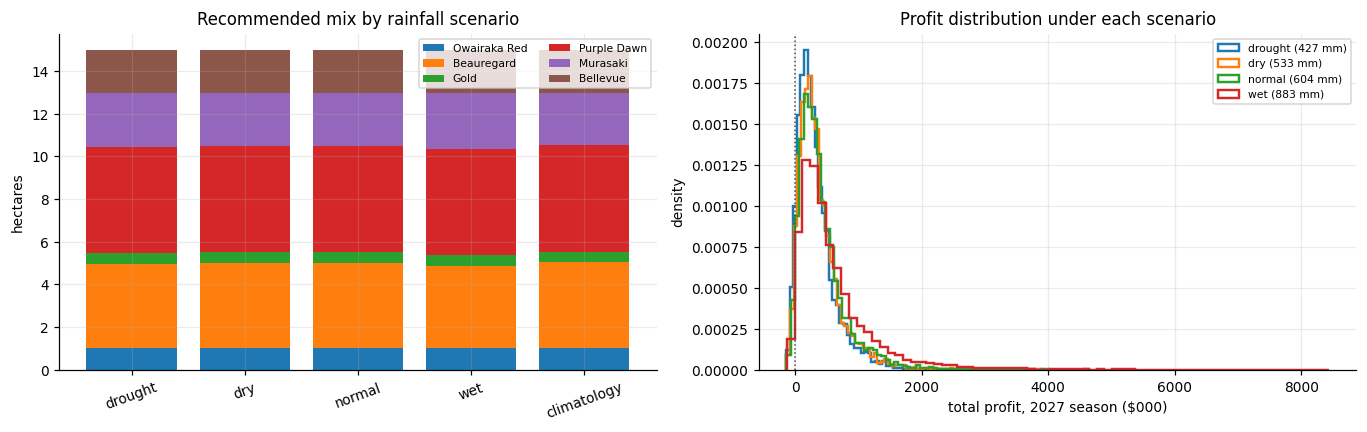

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))

x = np.arange(len(scen))
bot = np.zeros(len(scen))
for j, v in enumerate(CANDIDATES):
    h = np.array([r["w"][j] for r in scen])
    axes[0].bar(x, h, bottom=bot, label=v)
    bot += h
axes[0].set_xticks(x); axes[0].set_xticklabels([r["scenario"] for r in scen], rotation=20)
axes[0].set_ylabel("hectares"); axes[0].set_title("Recommended mix by rainfall scenario")
axes[0].legend(fontsize=7, ncol=2)

for r in scen:
    if r["scenario"] == "climatology":
        continue
    axes[1].hist(r["M"] @ r["w"] / 1000, bins=70, histtype="step", lw=1.6,
                 label=f"{r['scenario']} ({r['mm']:.0f} mm)", density=True)
axes[1].axvline(0, color="0.3", lw=1, ls=":")
axes[1].set_xlabel(f"total profit, {PLANTING_SEASON} season ($000)")
axes[1].set_ylabel("density"); axes[1].set_title("Profit distribution under each scenario")
axes[1].legend(fontsize=7)

plt.tight_layout(); plt.show()

tab.to_csv(OUT_DIR / f"rainfall_scenarios_{PLANTING_SEASON}.csv")

### 11.4 How dry before it hurts?

The scenarios above are five points on a curve; this sweeps rainfall continuously. The shaded
region is drier than any season on record, where the curve is a straight-line extrapolation the
data cannot vouch for. The dotted line marks where abandonment (section 8.1) starts.

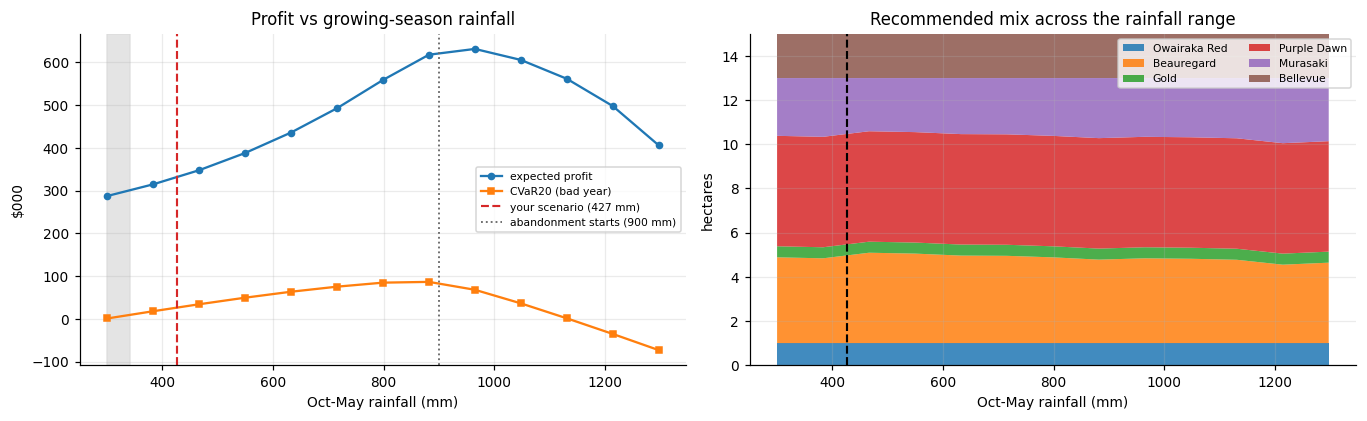

Expected profit peaks near 965 mm of Oct-May rain; worst-case (CVaR) profit peaks near 882 mm.
At 1298 mm (just past 2023, the wettest on record) expected profit is -36% against the best case, with 60% of the area abandoned.
At your 'drought' scenario (427 mm), expected profit is -21% against a median season.


In [36]:
sweep_mm = np.linspace(max(300, rain.min() * 0.85), rain.max() * 1.02, 13)
sweep = [run_scenario(float(m), sd_mm=60.0) for m in sweep_mm]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
axes[0].plot(sweep_mm, [r["mean"] / 1000 for r in sweep], "-o", ms=4, label="expected profit")
axes[0].plot(sweep_mm, [r["cvar"] / 1000 for r in sweep], "-s", ms=4,
             label=f"CVaR{int(CVAR_ALPHA*100)} (bad year)")
axes[0].axvspan(sweep_mm.min(), rain.min(), color="0.85", alpha=0.7, zorder=0)
axes[0].axvline(RAIN_CENTRE, color="C3", ls="--", lw=1.4,
                label=f"your scenario ({RAIN_CENTRE:.0f} mm)")
axes[0].axvline(HARVEST_LOSS["threshold_mm"], color="0.4", ls=":", lw=1.2,
                label=f"abandonment starts ({HARVEST_LOSS['threshold_mm']:.0f} mm)")
axes[0].set_xlabel("Oct-May rainfall (mm)"); axes[0].set_ylabel("$000")
axes[0].set_title("Profit vs growing-season rainfall"); axes[0].legend(fontsize=7)

W_sw = np.vstack([r["w"] for r in sweep])
axes[1].stackplot(sweep_mm, W_sw.T, labels=CANDIDATES, alpha=0.85)
axes[1].axvline(RAIN_CENTRE, color="k", ls="--", lw=1.4)
axes[1].set_xlabel("Oct-May rainfall (mm)"); axes[1].set_ylabel("hectares")
axes[1].set_title("Recommended mix across the rainfall range")
axes[1].legend(fontsize=7, ncol=2, loc="upper right"); axes[1].set_ylim(0, TOTAL_AREA_HA)

plt.tight_layout(); plt.show()

best = sweep_mm[int(np.argmax([r["mean"] for r in sweep]))]
bestc = sweep_mm[int(np.argmax([r["cvar"] for r in sweep]))]
print(f"Expected profit peaks near {best:.0f} mm of Oct-May rain; "
      f"worst-case (CVaR) profit peaks near {bestc:.0f} mm.")
_top = max(r["mean"] for r in sweep)
print(f"At {sweep_mm[-1]:.0f} mm (just past 2023, the wettest on record) expected profit is "
      f"{sweep[-1]['mean'] / _top - 1:+.0%} against the best case, with "
      f"{sweep[-1]['loss']:.0%} of the area abandoned.")
print(f"At your '{RAIN_SCENARIO}' scenario ({RAIN_CENTRE:.0f} mm), expected profit is "
      f"{(dro['mean']/base['mean'] - 1):+.0%} against a median season.")

### 11.5 How firm are these hectare figures?

The plan is optimised over 6,000 simulated seasons. A different 6,000 would give a slightly
different answer, and where several mixes are almost equally good, that can move whole hectares
between varieties. So the forecast and optimisation are re-run on twenty fresh sets of seasons. A
variety whose hectares barely move is a firm recommendation. One that swings is a toss-up: the
choice costs little either way, so decide it on seed, market or rotation.

If a recommended figure sits *outside* the range of the re-runs, the headline seasons landed at one
edge of a flat stretch, and the median column is the more representative plan. On the current run
every figure is inside its range. Only the Beauregard–Murasaki split moves, by about half a hectare
either way, and the alternative plans score within about $150 of the recommendation.

In [37]:
N_REPS = 20
reps = np.vstack([plan(simulate(RAIN_SCENARIO, seed=1000 + k)["margin"], seed=1000 + k)
                  for k in range(N_REPS)])


def score(w, M=MARGIN):
    "Risk-adjusted profit of an allocation on the headline seasons (higher is better)."
    return -objective(w, M, RISK_MEASURE, RISK_AVERSION, CVAR_ALPHA)


best_score = score(w_rec)
gaps = np.array([best_score - score(w) for w in reps])
lo_, hi_ = np.quantile(reps, 0.1, axis=0), np.quantile(reps, 0.9, axis=0)
firm = pd.DataFrame({
    "recommended ha": np.round(w_rec, 1),
    "median ha":      np.round(np.median(reps, axis=0), 1),
    "80% range":      [f"{a:.1f} - {b:.1f}" for a, b in zip(lo_, hi_)],
    "spread ha":      np.round(hi_ - lo_, 1),
}, index=CANDIDATES)
firm["verdict"] = np.select([firm["spread ha"] <= 0.5, firm["spread ha"] <= 1.5],
                            ["firm", "fairly firm"], default="toss-up")
display(firm)
print(f"Scored on the headline seasons, the {N_REPS} alternative plans fall short of the "
      f"recommendation on the optimiser's own")
print(f"risk-adjusted measure by a median ${np.median(gaps):,.0f} and at most ${gaps.max():,.0f} "
      f"- against an expected profit of ${summarise(MARGIN @ w_rec)['mean']:,.0f}.")
if (firm.verdict != "firm").any():
    print("Where a variety is not firm, moving its hectares within the range above costs about that much.")

,recommended ha,median ha,80% range,spread ha,verdict
Owairaka Red,1.0,1.0,1.0 - 1.0,0.0,firm
Beauregard,4.0,3.9,3.6 - 4.5,0.9,fairly firm
Gold,0.5,0.5,0.5 - 0.5,0.0,firm
Purple Dawn,5.0,5.0,5.0 - 5.0,0.0,firm
Murasaki,2.5,2.6,2.1 - 2.9,0.8,fairly firm
Bellevue,2.0,2.0,2.0 - 2.0,0.0,firm


Scored on the headline seasons, the 20 alternative plans fall short of the recommendation on the optimiser's own
risk-adjusted measure by a median $10 and at most $141 - against an expected profit of $333,527.
Where a variety is not firm, moving its hectares within the range above costs about that much.


### 11.6 Bellevue: what is your expectation worth?

Bellevue's numbers come from you, not from the data, so the plan largely hands your expectation
back to you. The useful questions are how much of it has to be true before Bellevue earns its area,
and what that area is worth.

The first table re-runs the forecast and the optimisation with Bellevue's advantage over Beauregard
scaled on the same simulated seasons throughout. The scale runs from −50% (half your expected
advantage, in reverse), through 0% (a Beauregard with its own paddock luck), to 150%. The second
table compares the recommended plan with the best plan that leaves Bellevue out.

**How to read it.** At parity (0%) Bellevue still takes its full 2 ha. It is effectively Beauregard
in separate paddocks, and spreading one crop over more blocks trims the paddock-luck risk a little.
So the row that answers "how good must it be" is where Bellevue drops *out*. On the current run it
keeps most of its area at a quarter of your advantage *worse* than Beauregard, and loses nearly all
of it at half. It earns its 2 ha as long as it is roughly no worse than Beauregard. Without it, the
plan puts the area back into Beauregard and Murasaki. The profit gap is what your expectation is
worth: about $7,800 of expected profit and $4,600 in a bad year this season.

In [38]:
for v, b in NEW_VARIETY_BELIEFS.items():
    j = CANDIDATES.index(v)
    rows = []
    for k in [-0.5, -0.25, 0.0, 0.25, 0.5, 1.0, 1.5]:
        bk = {**b, "yield_vs_like": {s: 1 + k * (r - 1) for s, r in b["yield_vs_like"].items()},
              "premium_pp": k * b["premium_pp"]}
        sim_k = simulate(RAIN_SCENARIO, beliefs={**NEW_VARIETY_BELIEFS, v: bk})
        w = plan(sim_k["margin"])
        st_k = summarise(sim_k["margin"] @ w)
        rows.append({"share of your expected advantage": f"{k:.0%}",
                     "yield vs " + b["like"]: " / ".join(f"{s} {r:.2f}"
                                                         for s, r in bk["yield_vs_like"].items()),
                     "Premium +pts": round(bk["premium_pp"], 1),
                     f"{v} ha": round(w[j], 1),
                     "E[profit]": round(st_k["mean"]),
                     f"CVaR{int(CVAR_ALPHA*100)}": round(st_k["cvar"])})
    print(f"{v}: how much of your expected advantage does it need? ('{RAIN_SCENARIO}' scenario)")
    display(pd.DataFrame(rows).set_index("share of your expected advantage"))

    w_wo = plan(MARGIN, max_area={**MAX_AREA_HA, v: 0.0})
    st_wo, st_w = summarise(MARGIN @ w_wo), summarise(MARGIN @ w_rec)
    cmp_ = pd.DataFrame([{"plan": f"recommended (with {v})", **{c: round(x, 1) for c, x in zip(CANDIDATES, w_rec)},
                          "E[profit]": round(st_w["mean"]), f"CVaR{int(CVAR_ALPHA*100)}": round(st_w["cvar"])},
                         {"plan": f"best without {v}", **{c: round(x, 1) for c, x in zip(CANDIDATES, w_wo)},
                          "E[profit]": round(st_wo["mean"]), f"CVaR{int(CVAR_ALPHA*100)}": round(st_wo["cvar"])}]
                        ).set_index("plan")
    display(cmp_)
    print(f"Under your expectation, {v} is worth {st_w['mean'] - st_wo['mean']:+,.0f} of expected "
          f"profit and {st_w['cvar'] - st_wo['cvar']:+,.0f} in a bad year (CVaR) this season.")

Bellevue: how much of your expected advantage does it need? ('drought' scenario)


,yield vs Beauregard,Premium +pts,Bellevue ha,E[profit],CVaR20
share of your expected advantage,,,,,
-50%,drought 0.97 / wet 0.90,-5.0,0.2,325355,20469
-25%,drought 0.99 / wet 0.95,-2.5,1.8,323511,20850
0%,drought 1.00 / wet 1.00,0.0,2.0,325250,21662
25%,drought 1.01 / wet 1.05,2.5,2.0,327231,22491
50%,drought 1.02 / wet 1.10,5.0,2.0,329291,23332
100%,drought 1.05 / wet 1.20,10.0,2.0,333527,25049
150%,drought 1.08 / wet 1.30,15.0,2.0,337888,26810


,Owairaka Red,Beauregard,Gold,Purple Dawn,Murasaki,Bellevue,E[profit],CVaR20
plan,,,,,,,,
recommended (with Bellevue),1.0,4.0,0.5,5.0,2.5,2.0,333527,25049
best without Bellevue,1.0,5.5,0.5,5.0,3.0,0.0,325711,20466


Under your expectation, Bellevue is worth +7,816 of expected profit and +4,583 in a bad year (CVaR) this season.


## 12. Caveats — read before acting

**What the numbers assume that the data cannot tell you:**

1. **Cost is your input, but it cannot change the mix.** `COST_PER_HA` is a placeholder. It sets
   expected profit, the probability of a loss, and whether the marginal hectare is worth planting,
   but not which varieties to plant (section 11.1). The exception is if particular varieties
   systematically land on dearer paddocks.
2. **The area limits do most of the work.** The optimiser pushes the best variety until a limit
   stops it, and on the current run four of the six varieties sit on one (section 11). Make sure
   `MIN_AREA_HA` / `MAX_AREA_HA` are your real limits on seed, market and rotation, the Purple Dawn
   and Bellevue ceilings above all.
3. **Murasaki is priced on one delivery**: January 2026, 10 bins at $1.37/kg net, in a season when
   Purple Dawn averaged about $2.25. That is all the price and bin-weight evidence there is, although
   the Bin Tally records Murasaki harvests in 2024–2026. Partial pooling pulls its premium most of
   the way to an average variety's. It is in the plan mostly because Beauregard's premium has slid
   (caveat 19), not because of its own evidence; its forecast price in the drought scenario ($1.32)
   rests on that one sheet. If it sells outside Kaipara or at a premium, set `PRICE_OVERRIDE` to a
   **typical-season** price, and the drought and season swings will apply on top. A risk-averse
   objective will also under-plant a variety this uncertain. That is correct behaviour, but it means
   the model can never *discover* a good new variety, only tell you what finding out costs.
4. **Not every sellable bin becomes a packout delivery.** Packout bins run below tally sellable bins
   for most seasons and varieties (median ratio about 0.83), and a few are far out the other way
   (2016 Owairaka Red, and Gold in 2024 and 2025). Causes include the timing gap between the tally's
   `season` and the packout's `year_folder`, fruit sold outside Kaipara, and thin record-keeping.
   Revenue assumes every sellable bin is paid at packout rates, which is optimistic.
5. **Price basis.** `total_payout / nett_kgs` and the sheet's printed `avg_nett_per_kg` differ by a
   median $0.23/kg (correlation 0.85). The computed figure is the default. If switching
   `PRICE_BASIS` to `"sheet"` changes your decision, resolve the discrepancy at source first.
6. **OCR damage, labels and duplicates.** The filters remove the obvious dollar-column errors but do
   not fix the data. Summary labels are corrected from the detail lines and duplicate scans are
   removed (section 3). A page whose detail is itself mislabelled, or a duplicate scanned with
   different figures, cannot be caught that way. Kilogram and bin figures are unaffected by the
   dollar OCR problem, so the yield side is on firmer ground than the dollar side.
7. **Areas are a current snapshot** applied to every season. Paddock boundaries have changed since
   2014 (the 17/18 merge is documented; others may not be), so older yields per hectare carry an
   unknown area error. Fenney Block has no recorded areas and is excluded.
8. **Area within shared paddocks is an estimate**, split by rows harvested or, where rows were not
   recorded, more crudely. Area weighting limits a small strip's influence but cannot fix an
   attribution error.
9. **Abandonment rests on one season.** The slope is fitted to 2023, site by site (Hodgson lost 57%
   of its planted area, Te Kowhai 5%). The 900 mm threshold is a judgement: the record only places
   the cliff between 2026 (918 mm, nothing lost) and 2023 (1272 mm). It dominates the wet-tail risk
   and does not touch the drought answer.
10. **Abandonment hits every variety alike.** One season cannot say whether some varieties rot or
    strand more readily.
11. **Site differences rest on few paddocks for most varieties.** Owairaka Red and Beauregard have
    dozens of paddocks at both sites; Purple Dawn, Gold and Murasaki have fewer than ten at Hodgson,
    so their Hodgson effects mostly follow the farm-wide pattern (section 5.3).
12. **The drought answer rests on two seasons**, 2014 (341 mm) and 2020 (484 mm), and a scenario
    drier than 341 mm is outside the record. The linear Jan–Feb term implies that less rain always
    means more yield, which cannot hold, because bulking needs water. **If your drought runs dry
    through January and February, expect the model to be optimistic about yield.** Its drought
    pessimism comes mainly through **price** (a dry year means a big national crop and weak returns),
    which is the better-evidenced half. Treat drought numbers as direction and rough size, not a
    precise forecast.
13. **The rainfall specification is a choice.** Yield uses three linear windows and price two. Both
    were chosen on adjusted R² and physical reasoning, and both hold up when 2023 is dropped
    (section 4). Other reasonable choices would move the numbers.
14. **Rainfall is ERA5 reanalysis, not your rain gauge.** It is a gridded reconstruction that smooths
    local extremes. Gauge records would drop straight in (`Rainfall_Data/README.md`).
15. **A few numbers per season hide a lot.** Steady rain and one storm make different seasons, and
    how the ground drains matters as much as the depth. Gabrielle's 264 mm counts in the *growing*
    window, although much of its damage was to the harvest. `monthly_rainfall.csv` allows finer
    windows, but eight monthly predictors on 13 seasons would need real structure (a smooth or a
    random walk across months) to avoid fitting noise. The model also sees rain, not irrigation.
16. **Varietal drought tolerance is barely identified.** With 13 seasons, two of them dry, a small
    `sigma_rain_variety` is partly genuine and partly an absence of evidence. Do not read an
    unchanged mix across scenarios as proof that variety choice is irrelevant in a drought; your own
    agronomic knowledge is better evidence here.
17. **No trend, no agronomy.** Season effects are exchangeable: 2027 is treated as no more like 2026
    than 2015, and there is no trend in the market price level. The model knows nothing about
    rotation, disease, soil type, planting date or storage life. Those enter through
    `MIN_AREA_HA` / `MAX_AREA_HA`.
18. **2016 has only two Bin Tally rows**, so its yield season effect is shrunk almost entirely to
    the mean.
19. **Premiums drift, and the forecast starts from the latest season.** That is what holds
    Beauregard's share down. The 2026 packout season is still coming in, so Beauregard's slide may
    partly reverse or deepen. Set `PRICE_PREMIUM_DRIFT = False` to see the plan on 12-year-average
    premiums; the gap between the two plans is the value of believing the recent trend.
20. **Bellevue is your expectation, not data.** It is simulated as Beauregard (same drought
    response, site effect, bin weight and price risk) scaled by `NEW_VARIETY_BELIEFS`. The Premium
    figure (+10 ± 5 points) is a placeholder. Rot resistance enters through yield only: abandonment
    is the same for every variety, since standing water strands any crop. The 0.11 ha Bellevue strip
    in the Bin Tally is not used in the forecast.

**Next steps, roughly in order of value:**

- **Pin down Murasaki's price.** If you know what the 2024–2026 crop sold for (outside Kaipara, or
  under a Purple label), put a typical-season figure in `PRICE_OVERRIDE` and re-run. A few real
  prices will do more for the Murasaki decision than anything else here.
- **Set Bellevue's Premium grade-out.** `premium_pp` is a placeholder (+10 points). Bellevue earns
  its 2 ha unless it is worse than Beauregard (section 11.6), so this mostly changes the profit,
  not the plan.
- **Check the Purple Dawn and Bellevue ceilings.** The plan depends on them most.
- **Fix the six mislabelled summary pages and the duplicate scans at source** (listed when section
  3 runs). Resolving invoice 803 page 2 restores a Purple Dawn delivery.
- **Keep flagging abandoned paddocks every season**, including partial abandonment. A second
  recorded wet season would turn the 900 mm threshold from a judgement into an estimate.
- **Test the threshold.** Re-run with `HARVEST_LOSS["threshold_mm"]` at 800 and 1000 mm.
- Model the grade mix directly. A hierarchical model of Premium share by variety and season
  (section 3.3) would let the price model *explain* Beauregard's decline rather than just track it.
- Reconcile tally and packout bins per season (caveat 4), and apply the ratio as a per-variety
  sale-rate factor.
- Swap ERA5 for gauge records if you can. **Feb–May** accuracy matters most for price, and the
  season total for abandonment.
- If you believe some varieties handle a dry year badly, a tighter `MAX_AREA_HA` on them will do
  more for the plan than the interaction term can.